# Лабораторная работа 3

Белдинова М.С., группа 6233, вариант 4 (набор данных MNIST)

1) Полносвязная нейронная сеть (Fully-Connected Neural Network)

2) Нормализация по мини-батчам (Batch normalization)

3) Dropout

4) Сверточные нейронные сети (Convolutional Networks)

# Полносвязная нейронная сеть

Полносвязная сеть реализуется модульно: для каждого слоя пишутся функции прямого и обратного прохода.

```python
def layer_forward(x, w):
  z = ...                 # промежуточные значения
  out = ...               # выход слоя
  cache = (x, w, z, out)  # все, что понадобится для градиентов
  return out, cache

def layer_backward(dout, cache):
  x, w, z, out = cache
  dx = ...  # dL/dx
  dw = ...  # dL/dw
  return dx, dw
```

In [1]:
import time
from math import sqrt, ceil
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def print_mean_std(x, axis=0):
    print('  means: ', x.mean(axis=axis))
    print('  stds:  ', x.std(axis=axis))
    print()

Численные градиенты для проверки реализаций и функция для визуализации весов.

In [2]:
def eval_numerical_gradient(f, x, verbose=True, h=0.00001):
    """численный градиент скалярной функции f в точке x"""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h
        fxph = f(x)
        x[ix] = oldval - h
        fxmh = f(x)
        x[ix] = oldval
        grad[ix] = (fxph - fxmh) / (2 * h)
        if verbose:
            print(ix, grad[ix])
        it.iternext()
    return grad


def eval_numerical_gradient_array(f, x, df, h=1e-5):
    """численный градиент для функции, возвращающей массив; df - градиент по выходу"""
    grad = np.zeros_like(x)
    it = np.nditer(x, flags=['multi_index'], op_flags=['readwrite'])
    while not it.finished:
        ix = it.multi_index
        oldval = x[ix]
        x[ix] = oldval + h
        pos = f(x).copy()
        x[ix] = oldval - h
        neg = f(x).copy()
        x[ix] = oldval
        grad[ix] = np.sum((pos - neg) * df) / (2 * h)
        it.iternext()
    return grad


def visualize_grid(Xs, ubound=255.0, padding=1):
    """Xs: (N, H, W, C) -> одна картинка-сетка"""
    (N, H, W, C) = Xs.shape
    grid_size = int(ceil(sqrt(N)))
    grid_height = H * grid_size + padding * (grid_size - 1)
    grid_width = W * grid_size + padding * (grid_size - 1)
    grid = np.zeros((grid_height, grid_width, C))
    next_idx = 0
    y0, y1 = 0, H
    for y in range(grid_size):
        x0, x1 = 0, W
        for x in range(grid_size):
            if next_idx < N:
                img = Xs[next_idx]
                low, high = np.min(img), np.max(img)
                grid[y0:y1, x0:x1] = ubound * (img - low) / max(high - low, 1e-12)
                next_idx += 1
            x0 += W + padding
            x1 += W + padding
        y0 += H + padding
        y1 += H + padding
    return grid

Загрузка данных из предыдущей лабораторной работы (MNIST, `load_digits`, изображения 1x8x8).

Данные хранятся в формате (N, C, H, W), как требуется для сверточных слоев; полносвязные слои сами вытягивают изображение в вектор. Предобработка: вычитаем среднее изображение по обучающей выборке и делим на общее стандартное отклонение, чтобы признаки были порядка единицы.

In [3]:
def get_digits_data(num_val=180, num_test=360, seed=0):
    digits = load_digits()
    X = digits.images.astype(np.float64)[:, None, :, :]   # (N, 1, 8, 8)
    y = digits.target.astype(np.int64)

    perm = np.random.RandomState(seed).permutation(X.shape[0])
    X, y = X[perm], y[perm]

    X_test, y_test = X[:num_test], y[:num_test]
    X_val, y_val = X[num_test:num_test + num_val], y[num_test:num_test + num_val]
    X_train, y_train = X[num_test + num_val:], y[num_test + num_val:]

    mean_image = X_train.mean(axis=0)
    std = X_train.std()
    X_train = (X_train - mean_image) / std
    X_val = (X_val - mean_image) / std
    X_test = (X_test - mean_image) / std

    return {'X_train': X_train, 'y_train': y_train,
            'X_val': X_val, 'y_val': y_val,
            'X_test': X_test, 'y_test': y_test}

data = get_digits_data()
for k, v in data.items():
    print('%s: ' % k, v.shape)

X_train:  (1257, 1, 8, 8)
y_train:  (1257,)
X_val:  (180, 1, 8, 8)
y_val:  (180,)
X_test:  (360, 1, 8, 8)
y_test:  (360,)


Прямой проход полносвязного слоя - `affine_forward`.

In [4]:
def affine_forward(x, w, b):
    """
    x: (N, d_1, ..., d_k) - вход, вытягивается в (N, D)
    w: (D, M), b: (M,)
    out: (N, M)
    """
    out = x.reshape(x.shape[0], -1).dot(w) + b
    cache = (x, w, b)
    return out, cache

In [5]:
num_inputs = 2
input_shape = (4, 5, 6)
output_dim = 3

input_size = num_inputs * np.prod(input_shape)
weight_size = output_dim * np.prod(input_shape)

x = np.linspace(-0.1, 0.5, num=input_size).reshape(num_inputs, *input_shape)
w = np.linspace(-0.2, 0.3, num=weight_size).reshape(np.prod(input_shape), output_dim)
b = np.linspace(-0.3, 0.1, num=output_dim)

out, _ = affine_forward(x, w, b)
correct_out = np.array([[ 1.49834967,  1.70660132,  1.91485297],
                        [ 3.25553199,  3.5141327,   3.77273342]])

print('Testing affine_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing affine_forward function:
difference:  9.769849468192957e-10


Обратный проход полносвязного слоя - `affine_backward`.

In [6]:
def affine_backward(dout, cache):
    """dout: (N, M) -> dx (как x), dw (D, M), db (M,)"""
    x, w, b = cache
    x_flat = x.reshape(x.shape[0], -1)
    dx = dout.dot(w.T).reshape(x.shape)
    dw = x_flat.T.dot(dout)
    db = np.sum(dout, axis=0)
    return dx, dw, db

In [7]:
np.random.seed(231)
x = np.random.randn(10, 2, 3)
w = np.random.randn(6, 5)
b = np.random.randn(5)
dout = np.random.randn(10, 5)

dx_num = eval_numerical_gradient_array(lambda x: affine_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_forward(x, w, b)[0], b, dout)

_, cache = affine_forward(x, w, b)
dx, dw, db = affine_backward(dout, cache)

print('Testing affine_backward function:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_backward function:
dx error:  5.399100368651805e-11
dw error:  9.904211865398145e-11
db error:  2.4122867568119087e-11


Прямой проход для слоя активации ReLU (`relu_forward`).

In [8]:
def relu_forward(x):
    out = np.maximum(0, x)
    cache = x
    return out, cache

In [9]:
x = np.linspace(-0.5, 0.5, num=12).reshape(3, 4)

out, _ = relu_forward(x)
correct_out = np.array([[ 0.,          0.,          0.,          0.,        ],
                        [ 0.,          0.,          0.04545455,  0.13636364,],
                        [ 0.22727273,  0.31818182,  0.40909091,  0.5,       ]])

# ошибка должна быть порядка e-8
print('Testing relu_forward function:')
print('difference: ', rel_error(out, correct_out))

Testing relu_forward function:
difference:  4.999999798022158e-08


Обратный проход для ReLU (`relu_backward`).

In [10]:
def relu_backward(dout, cache):
    x = cache
    dx = dout * (x > 0)
    return dx

In [11]:
np.random.seed(231)
x = np.random.randn(10, 10)
dout = np.random.randn(*x.shape)

dx_num = eval_numerical_gradient_array(lambda x: relu_forward(x)[0], x, dout)

_, cache = relu_forward(x)
dx = relu_backward(dout, cache)

# ошибка должна быть порядка e-12
print('Testing relu_backward function:')
print('dx error: ', rel_error(dx_num, dx))

Testing relu_backward function:
dx error:  3.2756349136310288e-12


Функции потерь (softmax и SVM), которые используются на выходе сетей, и часто используемые комбинации слоев: affine + ReLU.

In [12]:
def svm_loss(x, y):
    N = x.shape[0]
    correct_class_scores = x[np.arange(N), y]
    margins = np.maximum(0, x - correct_class_scores[:, np.newaxis] + 1.0)
    margins[np.arange(N), y] = 0
    loss = np.sum(margins) / N
    num_pos = np.sum(margins > 0, axis=1)
    dx = np.zeros_like(x)
    dx[margins > 0] = 1
    dx[np.arange(N), y] -= num_pos
    dx /= N
    return loss, dx


def softmax_loss(x, y):
    """x: (N, C) оценки классов, y: (N,) метки -> loss, dx"""
    shifted_logits = x - np.max(x, axis=1, keepdims=True)
    Z = np.sum(np.exp(shifted_logits), axis=1, keepdims=True)
    log_probs = shifted_logits - np.log(Z)
    probs = np.exp(log_probs)
    N = x.shape[0]
    loss = -np.sum(log_probs[np.arange(N), y]) / N
    dx = probs.copy()
    dx[np.arange(N), y] -= 1
    dx /= N
    return loss, dx


def affine_relu_forward(x, w, b):
    a, fc_cache = affine_forward(x, w, b)
    out, relu_cache = relu_forward(a)
    cache = (fc_cache, relu_cache)
    return out, cache


def affine_relu_backward(dout, cache):
    fc_cache, relu_cache = cache
    da = relu_backward(dout, relu_cache)
    dx, dw, db = affine_backward(da, fc_cache)
    return dx, dw, db

In [13]:
np.random.seed(231)
x = np.random.randn(2, 3, 4)
w = np.random.randn(12, 10)
b = np.random.randn(10)
dout = np.random.randn(2, 10)

out, cache = affine_relu_forward(x, w, b)
dx, dw, db = affine_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: affine_relu_forward(x, w, b)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: affine_relu_forward(x, w, b)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: affine_relu_forward(x, w, b)[0], b, dout)

# ошибка порядка e-10 или меньше
print('Testing affine_relu_forward and affine_relu_backward:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing affine_relu_forward and affine_relu_backward:
dx error:  2.299579177309368e-11
dw error:  8.162011105764925e-11
db error:  7.826724021458994e-12


Двухслойная полносвязная сеть - класс TwoLayerNet: affine - relu - affine - softmax. По умолчанию размер входа 8 * 8 = 64 (наши изображения).

In [14]:
class TwoLayerNet(object):

    def __init__(self, input_dim=1 * 8 * 8, hidden_dim=100, num_classes=10,
                 weight_scale=1e-3, reg=0.0):
        self.params = {}
        self.reg = reg
        self.params['W1'] = weight_scale * np.random.randn(input_dim, hidden_dim)
        self.params['b1'] = np.zeros(hidden_dim)
        self.params['W2'] = weight_scale * np.random.randn(hidden_dim, num_classes)
        self.params['b2'] = np.zeros(num_classes)

    def loss(self, X, y=None):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']

        h, cache1 = affine_relu_forward(X, W1, b1)
        scores, cache2 = affine_forward(h, W2, b2)

        if y is None:
            return scores

        grads = {}
        loss, dscores = softmax_loss(scores, y)
        loss += 0.5 * self.reg * (np.sum(W1 * W1) + np.sum(W2 * W2))

        dh, grads['W2'], grads['b2'] = affine_backward(dscores, cache2)
        _, grads['W1'], grads['b1'] = affine_relu_backward(dh, cache1)
        grads['W2'] += self.reg * W2
        grads['W1'] += self.reg * W1

        return loss, grads

In [15]:
np.random.seed(231)
N, D, H, C = 3, 5, 50, 7
X = np.random.randn(N, D)
y = np.random.randint(C, size=N)

std = 1e-3
model = TwoLayerNet(input_dim=D, hidden_dim=H, num_classes=C, weight_scale=std)

print('Testing initialization ... ')
W1_std = abs(model.params['W1'].std() - std)
b1 = model.params['b1']
W2_std = abs(model.params['W2'].std() - std)
b2 = model.params['b2']
assert W1_std < std / 10, 'First layer weights do not seem right'
assert np.all(b1 == 0), 'First layer biases do not seem right'
assert W2_std < std / 10, 'Second layer weights do not seem right'
assert np.all(b2 == 0), 'Second layer biases do not seem right'

print('Testing test-time forward pass ... ')
model.params['W1'] = np.linspace(-0.7, 0.3, num=D*H).reshape(D, H)
model.params['b1'] = np.linspace(-0.1, 0.9, num=H)
model.params['W2'] = np.linspace(-0.3, 0.4, num=H*C).reshape(H, C)
model.params['b2'] = np.linspace(-0.9, 0.1, num=C)
X = np.linspace(-5.5, 4.5, num=N*D).reshape(D, N).T
scores = model.loss(X)
correct_scores = np.asarray(
  [[11.53165108,  12.2917344,   13.05181771,  13.81190102,  14.57198434, 15.33206765,  16.09215096],
   [12.05769098,  12.74614105,  13.43459113,  14.1230412,   14.81149128, 15.49994135,  16.18839143],
   [12.58373087,  13.20054771,  13.81736455,  14.43418138,  15.05099822, 15.66781506,  16.2846319 ]])
scores_diff = np.abs(scores - correct_scores).sum()
assert scores_diff < 1e-6, 'Problem with test-time forward pass'

print('Testing training loss (no regularization)')
y = np.asarray([0, 5, 1])
loss, grads = model.loss(X, y)
correct_loss = 3.4702243556
assert abs(loss - correct_loss) < 1e-10, 'Problem with training-time loss'

model.reg = 1.0
loss, grads = model.loss(X, y)
correct_loss = 26.5948426952
assert abs(loss - correct_loss) < 1e-10, 'Problem with regularization loss'

# ошибки порядка e-7 или меньше
for reg in [0.0, 0.7]:
    print('Running numeric gradient check with reg = ', reg)
    model.reg = reg
    loss, grads = model.loss(X, y)

    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False)
        print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Testing initialization ... 
Testing test-time forward pass ... 
Testing training loss (no regularization)
Running numeric gradient check with reg =  0.0


W1 relative error: 1.83e-08


W2 relative error: 3.12e-10
b1 relative error: 9.83e-09
b2 relative error: 4.33e-10
Running numeric gradient check with reg =  0.7
W1 relative error: 2.53e-07


W2 relative error: 2.85e-08
b1 relative error: 1.56e-08
b2 relative error: 7.76e-10


Правила обновления весов (пока только обычный SGD, остальные добавляются ниже) и класс Solver, который выполняет обучение: делит данные на мини-батчи, делает шаги оптимизации, раз в эпоху считает accuracy на обучающей и валидационной выборках и в конце оставляет параметры с лучшей accuracy на валидации.

In [16]:
def sgd(w, dw, config=None):
    """обычный стохастический градиентный спуск"""
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)
    w -= config['learning_rate'] * dw
    return w, config

In [17]:
class Solver(object):
    """
    Обучение модели с API model.params / model.loss(X, y).

    data: словарь с ключами X_train, y_train, X_val, y_val
    Необязательные параметры:
    - update_rule: имя функции обновления ('sgd', 'sgd_momentum', 'rmsprop', 'adam')
    - optim_config: гиперпараметры правила обновления (learning_rate и т.д.)
    - lr_decay: множитель шага после каждой эпохи
    - batch_size, num_epochs
    - print_every: печать loss каждые print_every итераций
    - verbose
    - num_train_samples: на скольких обучающих объектах считать train accuracy (None - на всех)
    - num_val_samples: аналогично для валидации
    """

    def __init__(self, model, data, **kwargs):
        self.model = model
        self.X_train = data['X_train']
        self.y_train = data['y_train']
        self.X_val = data['X_val']
        self.y_val = data['y_val']

        self.update_rule = kwargs.pop('update_rule', 'sgd')
        self.optim_config = kwargs.pop('optim_config', {})
        self.lr_decay = kwargs.pop('lr_decay', 1.0)
        self.batch_size = kwargs.pop('batch_size', 100)
        self.num_epochs = kwargs.pop('num_epochs', 10)
        self.num_train_samples = kwargs.pop('num_train_samples', 1000)
        self.num_val_samples = kwargs.pop('num_val_samples', None)
        self.print_every = kwargs.pop('print_every', 10)
        self.verbose = kwargs.pop('verbose', True)

        if len(kwargs) > 0:
            extra = ', '.join('"%s"' % k for k in list(kwargs.keys()))
            raise ValueError('Unrecognized arguments %s' % extra)

        # правило обновления ищем по имени среди функций, объявленных в блокноте
        if isinstance(self.update_rule, str):
            if self.update_rule not in globals():
                raise ValueError('Invalid update_rule "%s"' % self.update_rule)
            self.update_rule = globals()[self.update_rule]

        self._reset()

    def _reset(self):
        self.epoch = 0
        self.best_val_acc = 0
        self.best_params = {}
        self.loss_history = []
        self.train_acc_history = []
        self.val_acc_history = []

        # у каждого параметра своя копия конфигурации (velocity, cache, m, v ...)
        self.optim_configs = {}
        for p in self.model.params:
            d = {k: v for k, v in self.optim_config.items()}
            self.optim_configs[p] = d

    def _step(self):
        num_train = self.X_train.shape[0]
        batch_mask = np.random.choice(num_train, self.batch_size)
        X_batch = self.X_train[batch_mask]
        y_batch = self.y_train[batch_mask]

        loss, grads = self.model.loss(X_batch, y_batch)
        self.loss_history.append(loss)

        for p, w in self.model.params.items():
            dw = grads[p]
            config = self.optim_configs[p]
            next_w, next_config = self.update_rule(w, dw, config)
            self.model.params[p] = next_w
            self.optim_configs[p] = next_config

    def check_accuracy(self, X, y, num_samples=None, batch_size=100):
        N = X.shape[0]
        if num_samples is not None and N > num_samples:
            mask = np.random.choice(N, num_samples)
            N = num_samples
            X = X[mask]
            y = y[mask]

        num_batches = N // batch_size
        if N % batch_size != 0:
            num_batches += 1
        y_pred = []
        for i in range(num_batches):
            start = i * batch_size
            end = (i + 1) * batch_size
            scores = self.model.loss(X[start:end])
            y_pred.append(np.argmax(scores, axis=1))
        y_pred = np.hstack(y_pred)
        return np.mean(y_pred == y)

    def train(self):
        num_train = self.X_train.shape[0]
        iterations_per_epoch = max(num_train // self.batch_size, 1)
        num_iterations = self.num_epochs * iterations_per_epoch

        for t in range(num_iterations):
            self._step()

            if self.verbose and t % self.print_every == 0:
                print('(Iteration %d / %d) loss: %f' % (t + 1, num_iterations, self.loss_history[-1]))

            epoch_end = (t + 1) % iterations_per_epoch == 0
            if epoch_end:
                self.epoch += 1
                for k in self.optim_configs:
                    self.optim_configs[k]['learning_rate'] *= self.lr_decay

            first_it = (t == 0)
            last_it = (t == num_iterations - 1)
            if first_it or last_it or epoch_end:
                train_acc = self.check_accuracy(self.X_train, self.y_train,
                                                num_samples=self.num_train_samples)
                val_acc = self.check_accuracy(self.X_val, self.y_val,
                                              num_samples=self.num_val_samples)
                self.train_acc_history.append(train_acc)
                self.val_acc_history.append(val_acc)

                if self.verbose:
                    print('(Epoch %d / %d) train acc: %f; val_acc: %f' % (
                        self.epoch, self.num_epochs, train_acc, val_acc))

                if val_acc > self.best_val_acc:
                    self.best_val_acc = val_acc
                    self.best_params = {}
                    for k, v in self.model.params.items():
                        self.best_params[k] = v.copy()

        # в конце оставляем веса, лучшие на валидации
        self.model.params = self.best_params

Обучение TwoLayerNet с помощью Solver. Требуется не менее 50% верно классифицированных объектов на валидационном наборе.

In [18]:
np.random.seed(0)
model = TwoLayerNet(input_dim=64, hidden_dim=100, weight_scale=1e-1, reg=1e-3)
solver = Solver(model, data,
                update_rule='sgd',
                optim_config={'learning_rate': 3e-1},
                lr_decay=0.95,
                num_epochs=20, batch_size=100,
                print_every=50)
solver.train()
print('Best val accuracy: ', solver.best_val_acc)

(Iteration 1 / 240) loss: 2.272767
(Epoch 0 / 20) train acc: 0.353000; val_acc: 0.361111
(Epoch 1 / 20) train acc: 0.908000; val_acc: 0.844444
(Epoch 2 / 20) train acc: 0.947000; val_acc: 0.888889
(Epoch 3 / 20) train acc: 0.958000; val_acc: 0.927778
(Epoch 4 / 20) train acc: 0.969000; val_acc: 0.938889
(Iteration 51 / 240) loss: 0.256389
(Epoch 5 / 20) train acc: 0.968000; val_acc: 0.938889
(Epoch 6 / 20) train acc: 0.973000; val_acc: 0.950000


(Epoch 7 / 20) train acc: 0.978000; val_acc: 0.950000
(Epoch 8 / 20) train acc: 0.974000; val_acc: 0.950000
(Iteration 101 / 240) loss: 0.195730
(Epoch 9 / 20) train acc: 0.985000; val_acc: 0.955556
(Epoch 10 / 20) train acc: 0.980000; val_acc: 0.955556
(Epoch 11 / 20) train acc: 0.984000; val_acc: 0.961111
(Epoch 12 / 20) train acc: 0.986000; val_acc: 0.961111
(Iteration 151 / 240) loss: 0.102179
(Epoch 13 / 20) train acc: 0.986000; val_acc: 0.955556
(Epoch 14 / 20) train acc: 0.987000; val_acc: 0.961111


(Epoch 15 / 20) train acc: 0.990000; val_acc: 0.955556
(Epoch 16 / 20) train acc: 0.985000; val_acc: 0.961111
(Iteration 201 / 240) loss: 0.109722
(Epoch 17 / 20) train acc: 0.991000; val_acc: 0.961111
(Epoch 18 / 20) train acc: 0.991000; val_acc: 0.961111
(Epoch 19 / 20) train acc: 0.990000; val_acc: 0.961111
(Epoch 20 / 20) train acc: 0.994000; val_acc: 0.961111
Best val accuracy:  0.9611111111111111


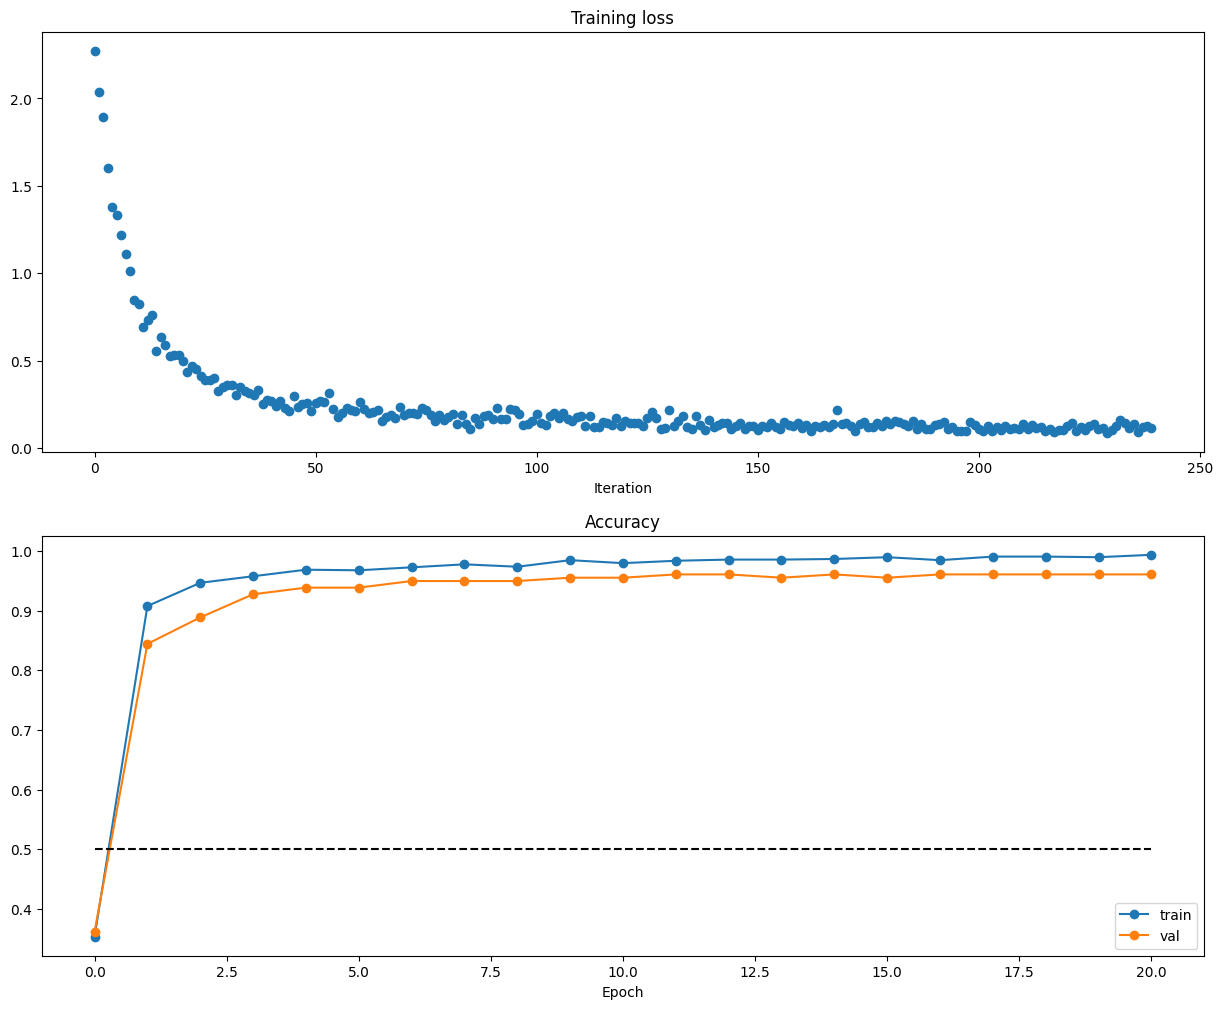

In [19]:
plt.subplot(2, 1, 1)
plt.title('Training loss')
plt.plot(solver.loss_history, 'o')
plt.xlabel('Iteration')

plt.subplot(2, 1, 2)
plt.title('Accuracy')
plt.plot(solver.train_acc_history, '-o', label='train')
plt.plot(solver.val_acc_history, '-o', label='val')
plt.plot([0.5] * len(solver.val_acc_history), 'k--')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.gcf().set_size_inches(15, 12)
plt.show()

Полносвязная сеть с произвольным числом скрытых слоев - класс FullyConnectedNet:

{affine - [batch norm] - relu - [dropout]} x (L - 1) - affine - softmax

Слои батч-нормализации и dropout используются ниже, сами функции этих слоев реализованы в соответствующих разделах (на момент вызова они уже объявлены). Сначала проверяется вариант без нормализации и без dropout.

In [20]:
class FullyConnectedNet(object):

    def __init__(self, hidden_dims, input_dim=1 * 8 * 8, num_classes=10,
                 dropout=1, normalization=None, reg=0.0,
                 weight_scale=1e-2, dtype=np.float32, seed=None):
        """
        hidden_dims - список размеров скрытых слоев
        dropout - вероятность СОХРАНИТЬ нейрон; dropout=1 означает, что dropout не используется
        normalization - None или 'batchnorm'
        reg - сила L2-регуляризации
        weight_scale - std нормального распределения для инициализации весов
        dtype - тип данных (float64 нужен для проверки градиентов)
        seed - фиксирует маску dropout (для проверки градиентов)
        """
        self.normalization = normalization
        self.use_dropout = dropout != 1
        self.reg = reg
        self.num_layers = 1 + len(hidden_dims)
        self.dtype = dtype
        self.params = {}

        dims = [input_dim] + list(hidden_dims) + [num_classes]
        for i in range(self.num_layers):
            self.params['W%d' % (i + 1)] = weight_scale * np.random.randn(dims[i], dims[i + 1])
            self.params['b%d' % (i + 1)] = np.zeros(dims[i + 1])
            # параметры масштаба и сдвига batchnorm только для скрытых слоев
            if self.normalization == 'batchnorm' and i < self.num_layers - 1:
                self.params['gamma%d' % (i + 1)] = np.ones(dims[i + 1])
                self.params['beta%d' % (i + 1)] = np.zeros(dims[i + 1])

        self.dropout_param = {}
        if self.use_dropout:
            self.dropout_param = {'mode': 'train', 'p': dropout}
            if seed is not None:
                self.dropout_param['seed'] = seed

        # для каждого слоя batchnorm свой словарь с бегущими средним и дисперсией
        self.bn_params = []
        if self.normalization == 'batchnorm':
            self.bn_params = [{'mode': 'train'} for i in range(self.num_layers - 1)]

        for k, v in self.params.items():
            self.params[k] = v.astype(dtype)

    def loss(self, X, y=None):
        X = X.astype(self.dtype)
        mode = 'test' if y is None else 'train'

        if self.use_dropout:
            self.dropout_param['mode'] = mode
        for bn_param in self.bn_params:
            bn_param['mode'] = mode

        caches = []
        drop_caches = []
        out = X
        for i in range(1, self.num_layers):
            W, b = self.params['W%d' % i], self.params['b%d' % i]
            if self.normalization == 'batchnorm':
                gamma, beta = self.params['gamma%d' % i], self.params['beta%d' % i]
                out, cache = affine_bn_relu_forward(out, W, b, gamma, beta, self.bn_params[i - 1])
            else:
                out, cache = affine_relu_forward(out, W, b)
            caches.append(cache)
            if self.use_dropout:
                out, dcache = dropout_forward(out, self.dropout_param)
                drop_caches.append(dcache)

        L = self.num_layers
        scores, last_cache = affine_forward(out, self.params['W%d' % L], self.params['b%d' % L])

        if mode == 'test':
            return scores

        grads = {}
        loss, dscores = softmax_loss(scores, y)
        for i in range(1, L + 1):
            W = self.params['W%d' % i]
            loss += 0.5 * self.reg * np.sum(W * W)

        dout, dW, db = affine_backward(dscores, last_cache)
        grads['W%d' % L] = dW + self.reg * self.params['W%d' % L]
        grads['b%d' % L] = db

        for i in range(L - 1, 0, -1):
            if self.use_dropout:
                dout = dropout_backward(dout, drop_caches[i - 1])
            if self.normalization == 'batchnorm':
                dout, dW, db, dgamma, dbeta = affine_bn_relu_backward(dout, caches[i - 1])
                grads['gamma%d' % i] = dgamma
                grads['beta%d' % i] = dbeta
            else:
                dout, dW, db = affine_relu_backward(dout, caches[i - 1])
            grads['W%d' % i] = dW + self.reg * self.params['W%d' % i]
            grads['b%d' % i] = db

        return loss, grads

In [21]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print('Running check with reg = ', reg)
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                              reg=reg, weight_scale=5e-2, dtype=np.float64)

    loss, grads = model.loss(X, y)
    print('Initial loss: ', loss)

    # большинство ошибок порядка e-7 и меньше
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))

Running check with reg =  0
Initial loss:  2.3004790897684924


W1 relative error: 1.48e-07


W2 relative error: 2.21e-05
W3 relative error: 3.53e-07
b1 relative error: 5.38e-09


b2 relative error: 2.09e-09
b3 relative error: 5.80e-11
Running check with reg =  3.14
Initial loss:  7.052114776533016


W1 relative error: 3.90e-09


W2 relative error: 6.87e-08


W3 relative error: 2.13e-08
b1 relative error: 1.48e-08
b2 relative error: 1.72e-09
b3 relative error: 1.57e-10


Переобучение на небольшом наборе (50 изображений): трехслойная сеть по 100 нейронов в скрытых слоях, цель - 100% accuracy на обучающей выборке за 20 эпох. Подбираются только weight_scale и learning_rate.

In [22]:
np.random.seed(231)
num_train = 50
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

# подбор по небольшой сетке
overfit3 = {}
for ws in [1e-2, 5e-2, 1e-1, 2e-1]:
    for lr in [1e-2, 5e-2, 1e-1, 2e-1]:
        np.random.seed(231)
        model = FullyConnectedNet([100, 100], weight_scale=ws, dtype=np.float64)
        s = Solver(model, small_data, num_epochs=20, batch_size=25,
                   update_rule='sgd', optim_config={'learning_rate': lr}, verbose=False)
        s.train()
        overfit3[(ws, lr)] = (s.train_acc_history[-1], s.loss_history[-1])
        print('weight_scale %.0e  lr %.0e  -> final train acc %.2f, final loss %.4f'
              % (ws, lr, s.train_acc_history[-1], s.loss_history[-1]))

weight_scale 1e-02  lr 1e-02  -> final train acc 0.16, final loss 2.2920


weight_scale 1e-02  lr 5e-02  -> final train acc 0.16, final loss 2.2562
weight_scale 1e-02  lr 1e-01  -> final train acc 0.16, final loss 2.2228


weight_scale 1e-02  lr 2e-01  -> final train acc 0.16, final loss 2.1801
weight_scale 5e-02  lr 1e-02  -> final train acc 0.24, final loss 2.2628


weight_scale 5e-02  lr 5e-02  -> final train acc 0.56, final loss 2.1233
weight_scale 5e-02  lr 1e-01  -> final train acc 0.58, final loss 1.7234
weight_scale 5e-02  lr 2e-01  -> final train acc 0.84, final loss 0.6781


weight_scale 1e-01  lr 1e-02  -> final train acc 0.36, final loss 1.9734
weight_scale 1e-01  lr 5e-02  -> final train acc 0.84, final loss 0.9313
weight_scale 1e-01  lr 1e-01  -> final train acc 0.96, final loss 0.3961


weight_scale 1e-01  lr 2e-01  -> final train acc 1.00, final loss 0.1287
weight_scale 2e-01  lr 1e-02  -> final train acc 0.88, final loss 0.7785
weight_scale 2e-01  lr 5e-02  -> final train acc 1.00, final loss 0.0894


weight_scale 2e-01  lr 1e-01  -> final train acc 1.00, final loss 0.0347
weight_scale 2e-01  lr 2e-01  -> final train acc 1.00, final loss 0.0145


weight_scale = 0.1, learning_rate = 0.2
(Iteration 1 / 40) loss: 2.411180
(Epoch 0 / 20) train acc: 0.180000; val_acc: 0.177778
(Epoch 1 / 20) train acc: 0.460000; val_acc: 0.316667
(Epoch 2 / 20) train acc: 0.660000; val_acc: 0.383333
(Epoch 3 / 20) train acc: 0.600000; val_acc: 0.388889
(Epoch 4 / 20) train acc: 0.720000; val_acc: 0.461111
(Epoch 5 / 20) train acc: 0.740000; val_acc: 0.500000
(Iteration 11 / 40) loss: 1.231407
(Epoch 6 / 20) train acc: 0.800000; val_acc: 0.566667
(Epoch 7 / 20) train acc: 0.960000; val_acc: 0.677778
(Epoch 8 / 20) train acc: 0.960000; val_acc: 0.700000
(Epoch 9 / 20) train acc: 0.960000; val_acc: 0.688889
(Epoch 10 / 20) train acc: 0.960000; val_acc: 0.705556
(Iteration 21 / 40) loss: 0.488826
(Epoch 11 / 20) train acc: 0.980000; val_acc: 0.694444
(Epoch 12 / 20) train acc: 1.000000; val_acc: 0.705556
(Epoch 13 / 20) train acc: 0.980000; val_acc: 0.705556
(Epoch 14 / 20) train acc: 1.000000; val_acc: 0.722222
(Epoch 15 / 20) train acc: 1.000000; val_

(Epoch 20 / 20) train acc: 1.000000; val_acc: 0.727778


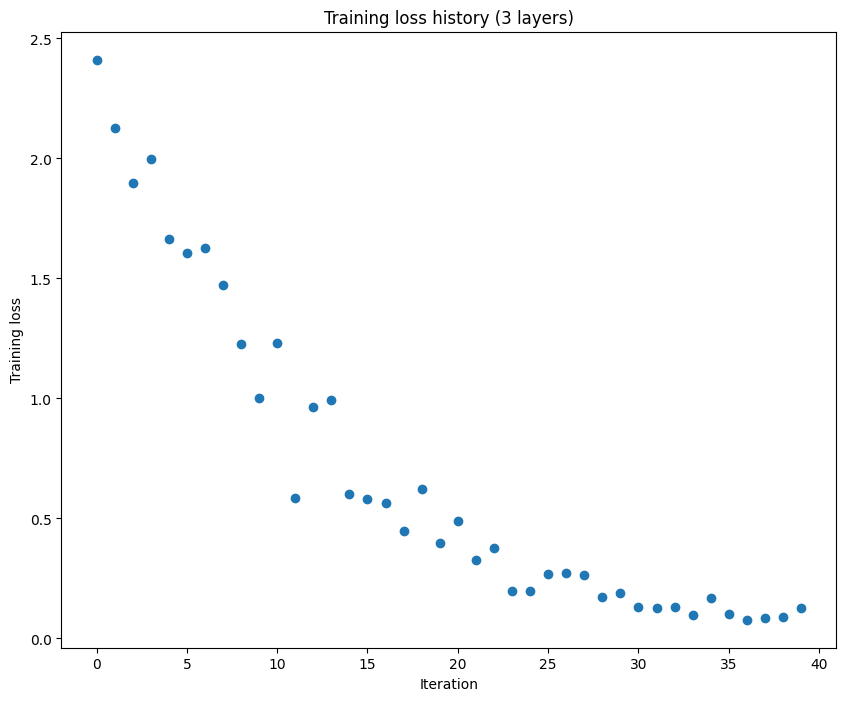

In [23]:
# берем самое маленькое weight_scale (а при равенстве - самый маленький шаг), при котором достигается 100%
weight_scale, learning_rate = min(k for k, v in overfit3.items() if v[0] == 1.0)
print('weight_scale = %g, learning_rate = %g' % (weight_scale, learning_rate))
np.random.seed(231)
model = FullyConnectedNet([100, 100],
              weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history (3 layers)')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()

Тот же эксперимент для пятислойной сети.

In [24]:
overfit5 = {}
for ws in [1e-2, 5e-2, 1e-1, 2e-1]:
    for lr in [1e-2, 5e-2, 1e-1, 2e-1]:
        np.random.seed(231)
        model = FullyConnectedNet([100, 100, 100, 100], weight_scale=ws, dtype=np.float64)
        s = Solver(model, small_data, num_epochs=20, batch_size=25,
                   update_rule='sgd', optim_config={'learning_rate': lr}, verbose=False)
        s.train()
        overfit5[(ws, lr)] = (s.train_acc_history[-1], s.loss_history[-1])
        print('weight_scale %.0e  lr %.0e  -> final train acc %.2f, final loss %.4f'
              % (ws, lr, s.train_acc_history[-1], s.loss_history[-1]))

weight_scale 1e-02  lr 1e-02  -> final train acc 0.16, final loss 2.2947
weight_scale 1e-02  lr 5e-02  -> final train acc 0.16, final loss 2.2691


weight_scale 1e-02  lr 1e-01  -> final train acc 0.16, final loss 2.2470
weight_scale 1e-02  lr 2e-01  -> final train acc 0.16, final loss 2.2225


weight_scale 5e-02  lr 1e-02  -> final train acc 0.16, final loss 2.2931
weight_scale 5e-02  lr 5e-02  -> final train acc 0.16, final loss 2.2627


weight_scale 5e-02  lr 1e-01  -> final train acc 0.16, final loss 2.2362
weight_scale 5e-02  lr 2e-01  -> final train acc 0.16, final loss 2.2020


weight_scale 1e-01  lr 1e-02  -> final train acc 0.28, final loss 2.1912
weight_scale 1e-01  lr 5e-02  -> final train acc 0.66, final loss 1.5370


weight_scale 1e-01  lr 1e-01  -> final train acc 0.94, final loss 0.4016
weight_scale 1e-01  lr 2e-01  -> final train acc 1.00, final loss 0.0439


weight_scale 2e-01  lr 1e-02  -> final train acc 1.00, final loss 0.1049
weight_scale 2e-01  lr 5e-02  -> final train acc 1.00, final loss 0.0154


weight_scale 2e-01  lr 1e-01  -> final train acc 1.00, final loss 0.0106
weight_scale 2e-01  lr 2e-01  -> final train acc 1.00, final loss 0.0075


weight_scale = 0.1, learning_rate = 0.2
(Iteration 1 / 40) loss: 2.234948
(Epoch 0 / 20) train acc: 0.160000; val_acc: 0.094444
(Epoch 1 / 20) train acc: 0.160000; val_acc: 0.094444
(Epoch 2 / 20) train acc: 0.260000; val_acc: 0.150000
(Epoch 3 / 20) train acc: 0.540000; val_acc: 0.266667


(Epoch 4 / 20) train acc: 0.640000; val_acc: 0.316667
(Epoch 5 / 20) train acc: 0.660000; val_acc: 0.250000
(Iteration 11 / 40) loss: 1.456955
(Epoch 6 / 20) train acc: 0.640000; val_acc: 0.350000
(Epoch 7 / 20) train acc: 0.760000; val_acc: 0.444444
(Epoch 8 / 20) train acc: 0.860000; val_acc: 0.505556
(Epoch 9 / 20) train acc: 0.780000; val_acc: 0.494444
(Epoch 10 / 20) train acc: 0.840000; val_acc: 0.600000
(Iteration 21 / 40) loss: 0.384877
(Epoch 11 / 20) train acc: 0.920000; val_acc: 0.572222
(Epoch 12 / 20) train acc: 0.920000; val_acc: 0.644444
(Epoch 13 / 20) train acc: 0.940000; val_acc: 0.700000
(Epoch 14 / 20) train acc: 0.860000; val_acc: 0.644444
(Epoch 15 / 20) train acc: 0.960000; val_acc: 0.711111
(Iteration 31 / 40) loss: 0.267863
(Epoch 16 / 20) train acc: 0.980000; val_acc: 0.711111
(Epoch 17 / 20) train acc: 1.000000; val_acc: 0.716667
(Epoch 18 / 20) train acc: 1.000000; val_acc: 0.711111
(Epoch 19 / 20) train acc: 1.000000; val_acc: 0.711111
(Epoch 20 / 20) train

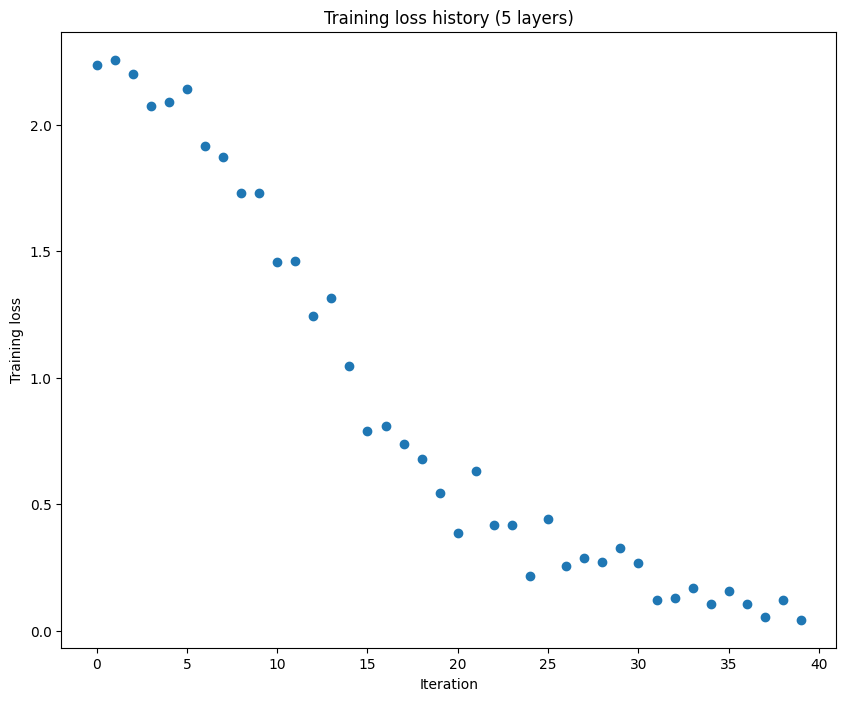

In [25]:
weight_scale, learning_rate = min(k for k, v in overfit5.items() if v[0] == 1.0)
print('weight_scale = %g, learning_rate = %g' % (weight_scale, learning_rate))
np.random.seed(231)
model = FullyConnectedNet([100, 100, 100, 100],
                weight_scale=weight_scale, dtype=np.float64)
solver = Solver(model, small_data,
                print_every=10, num_epochs=20, batch_size=25,
                update_rule='sgd',
                optim_config={
                  'learning_rate': learning_rate,
                }
         )
solver.train()

plt.plot(solver.loss_history, 'o')
plt.title('Training loss history (5 layers)')
plt.xlabel('Iteration')
plt.ylabel('Training loss')
plt.show()

Выводы по эксперименту.

**Выводы по эксперименту с переобучением:**

- Обе сети удается переобучить на 50 изображениях: train accuracy 100%, при этом val accuracy около 72-73%, то есть сеть запомнила обучающую выборку, но обобщает плохо.
- При маленьком weight_scale (1e-2) ни трехслойная, ни пятислойная сеть за 20 эпох не обучаются вообще (accuracy 16%, loss почти не меняется): сигнал и градиенты затухают, проходя через несколько слоев с маленькими весами.
- Пятислойная сеть заметно чувствительнее к инициализации: для нее диапазон рабочих значений weight_scale уже, и ей требуется более крупная инициализация (при weight_scale = 2e-1 она переобучается при любом шаге из сетки). Чем глубже сеть, тем важнее правильно выбрать масштаб начальных весов, что и мотивирует использование батч-нормализации и специальных схем инициализации.

SGD с импульсом (SGD+momentum): $v = \mu v - \alpha \nabla w$, $w = w + v$.

In [26]:
def sgd_momentum(w, dw, config=None):
    """
    config: learning_rate, momentum (0.9 по умолчанию),
    velocity - скользящее среднее градиентов (той же формы, что w)
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)
    config.setdefault('momentum', 0.9)
    v = config.get('velocity', np.zeros_like(w))

    v = config['momentum'] * v - config['learning_rate'] * dw
    next_w = w + v

    config['velocity'] = v
    return next_w, config

In [27]:
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
v = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-3, 'velocity': v}
next_w, _ = sgd_momentum(w, dw, config=config)

expected_next_w = np.asarray([
  [ 0.1406,      0.20738947,  0.27417895,  0.34096842,  0.40775789],
  [ 0.47454737,  0.54133684,  0.60812632,  0.67491579,  0.74170526],
  [ 0.80849474,  0.87528421,  0.94207368,  1.00886316,  1.07565263],
  [ 1.14244211,  1.20923158,  1.27602105,  1.34281053,  1.4096    ]])
expected_velocity = np.asarray([
  [ 0.5406,      0.55475789,  0.56891579, 0.58307368,  0.59723158],
  [ 0.61138947,  0.62554737,  0.63970526,  0.65386316,  0.66802105],
  [ 0.68217895,  0.69633684,  0.71049474,  0.72465263,  0.73881053],
  [ 0.75296842,  0.76712632,  0.78128421,  0.79544211,  0.8096    ]])

# относительные ошибки порядка e-8 или меньше
print('next_w error: ', rel_error(next_w, expected_next_w))
print('velocity error: ', rel_error(expected_velocity, config['velocity']))

next_w error:  8.882347033505819e-09
velocity error:  4.269287743278663e-09


Сравнение шестислойной сети, обученной обычным SGD и SGD с импульсом. Используется вся обучающая выборка (в нашем наборе 1257 изображений, меньше 4000 из шаблона), поэтому число эпох увеличено до 10. При weight_scale = 5e-2 из шаблона сигнал в 6-слойной сети почти затухает (std активаций уменьшается от слоя к слою) и за 120 итераций не обучается ни один из методов, поэтому взято weight_scale = 1e-1 и шаг 1e-2.

running with  sgd
(Iteration 1 / 120) loss: 2.304785
(Epoch 0 / 10) train acc: 0.053000; val_acc: 0.055556
(Epoch 1 / 10) train acc: 0.060000; val_acc: 0.055556


(Epoch 2 / 10) train acc: 0.077000; val_acc: 0.077778
(Epoch 3 / 10) train acc: 0.113000; val_acc: 0.100000
(Iteration 41 / 120) loss: 2.269872
(Epoch 4 / 10) train acc: 0.162000; val_acc: 0.150000


(Epoch 5 / 10) train acc: 0.245000; val_acc: 0.200000
(Epoch 6 / 10) train acc: 0.259000; val_acc: 0.222222
(Iteration 81 / 120) loss: 2.245508
(Epoch 7 / 10) train acc: 0.268000; val_acc: 0.272222


(Epoch 8 / 10) train acc: 0.335000; val_acc: 0.344444
(Epoch 9 / 10) train acc: 0.358000; val_acc: 0.388889


(Epoch 10 / 10) train acc: 0.386000; val_acc: 0.400000

running with  sgd_momentum
(Iteration 1 / 120) loss: 2.304785
(Epoch 0 / 10) train acc: 0.053000; val_acc: 0.055556
(Epoch 1 / 10) train acc: 0.161000; val_acc: 0.144444


(Epoch 2 / 10) train acc: 0.433000; val_acc: 0.411111
(Epoch 3 / 10) train acc: 0.472000; val_acc: 0.461111
(Iteration 41 / 120) loss: 1.885852
(Epoch 4 / 10) train acc: 0.460000; val_acc: 0.427778


(Epoch 5 / 10) train acc: 0.687000; val_acc: 0.672222
(Epoch 6 / 10) train acc: 0.793000; val_acc: 0.705556
(Iteration 81 / 120) loss: 0.556779
(Epoch 7 / 10) train acc: 0.838000; val_acc: 0.800000


(Epoch 8 / 10) train acc: 0.900000; val_acc: 0.866667
(Epoch 9 / 10) train acc: 0.920000; val_acc: 0.900000


(Epoch 10 / 10) train acc: 0.942000; val_acc: 0.900000



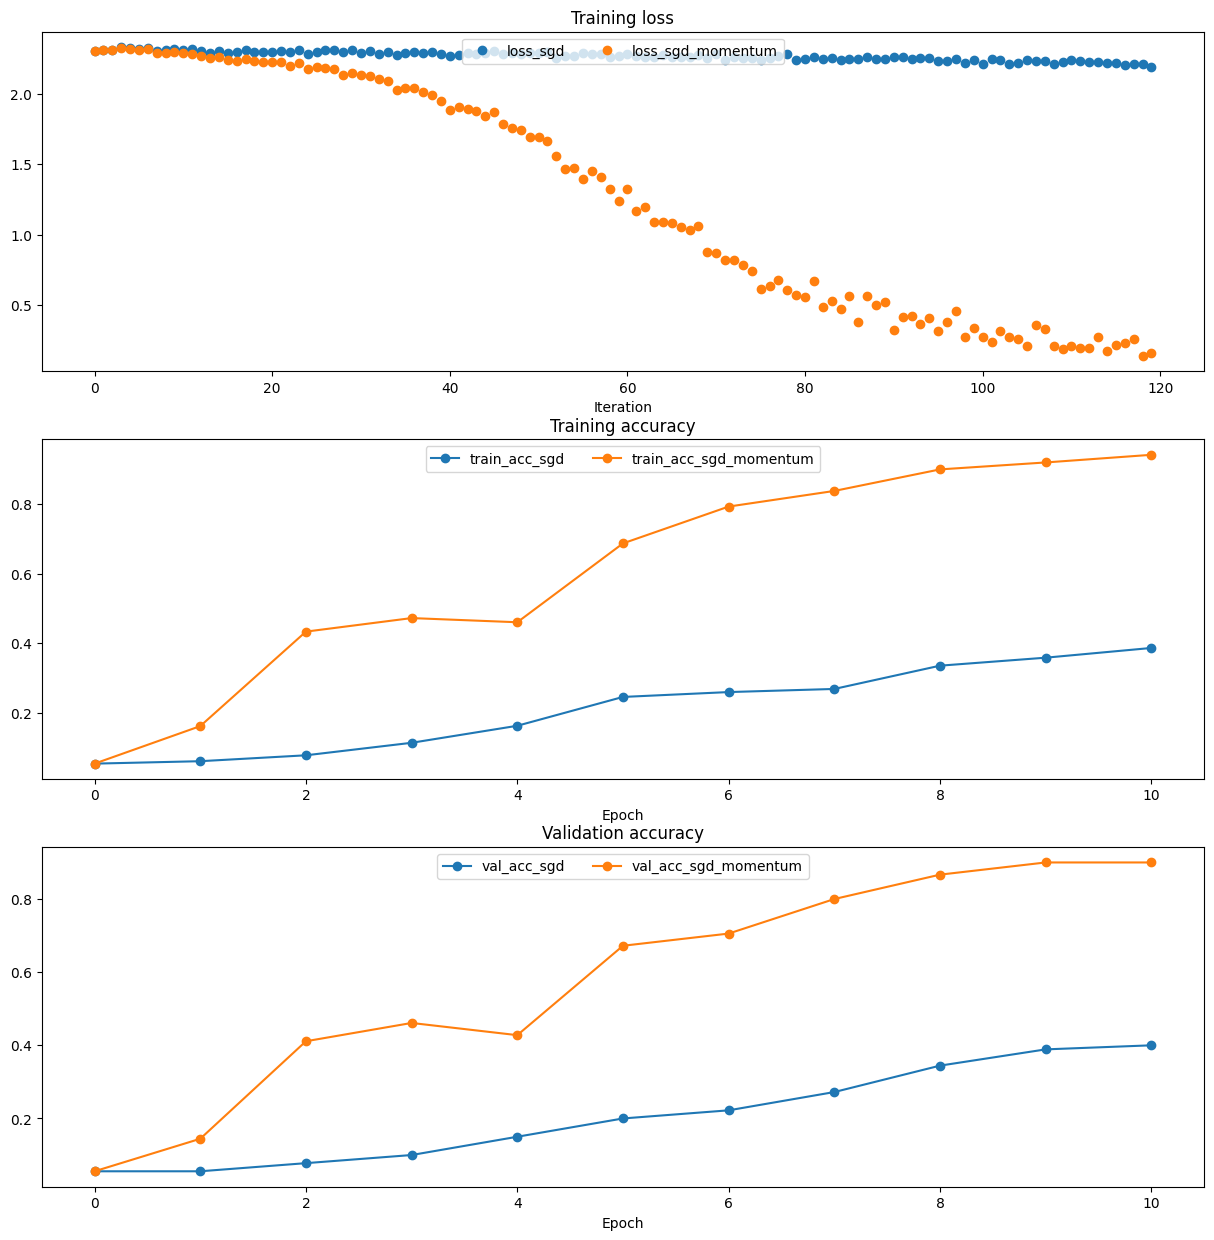

In [28]:
np.random.seed(231)
num_train = 4000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}

for update_rule in ['sgd', 'sgd_momentum']:
    print('running with ', update_rule)
    np.random.seed(231)
    model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=1e-1)

    solver = Solver(model, small_data,
                    num_epochs=10, batch_size=100,
                    update_rule=update_rule,
                    optim_config={
                      'learning_rate': 1e-2,
                    },
                    verbose=True, print_every=40)
    solvers[update_rule] = solver
    solver.train()
    print()

def plot_solvers(solvers):
    plt.subplot(3, 1, 1)
    plt.title('Training loss')
    plt.xlabel('Iteration')

    plt.subplot(3, 1, 2)
    plt.title('Training accuracy')
    plt.xlabel('Epoch')

    plt.subplot(3, 1, 3)
    plt.title('Validation accuracy')
    plt.xlabel('Epoch')

    for update_rule, solver in solvers.items():
        plt.subplot(3, 1, 1)
        plt.plot(solver.loss_history, 'o', label='loss_%s' % update_rule)

        plt.subplot(3, 1, 2)
        plt.plot(solver.train_acc_history, '-o', label='train_acc_%s' % update_rule)

        plt.subplot(3, 1, 3)
        plt.plot(solver.val_acc_history, '-o', label='val_acc_%s' % update_rule)

    for i in [1, 2, 3]:
        plt.subplot(3, 1, i)
        plt.legend(loc='upper center', ncol=4)
    plt.gcf().set_size_inches(15, 15)
    plt.show()

plot_solvers(solvers)

SGD с импульсом сходится существенно быстрее обычного SGD: при одинаковом шаге за 10 эпох обычный SGD только начинает уменьшать loss (около 2.2, лучшая val accuracy 40%), а SGD + momentum доходит до loss ~0.2 и val accuracy 90%. Импульс накапливает скорость вдоль устойчивого направления градиента и сглаживает колебания, поэтому эффективный шаг получается больше.

Алгоритмы RMSProp [1] и Adam [2] (с коррекцией смещения) - функции `rmsprop` и `adam`.

[1] Tijmen Tieleman and Geoffrey Hinton. "Lecture 6.5-rmsprop: Divide the gradient by a running average of its recent magnitude." COURSERA: Neural Networks for Machine Learning 4 (2012).

[2] Diederik Kingma and Jimmy Ba, "Adam: A Method for Stochastic Optimization", ICLR 2015.

In [29]:
def rmsprop(w, dw, config=None):
    """
    config: learning_rate, decay_rate, epsilon,
    cache - скользящее среднее квадратов градиента
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-2)
    config.setdefault('decay_rate', 0.99)
    config.setdefault('epsilon', 1e-8)
    config.setdefault('cache', np.zeros_like(w))

    cache = config['decay_rate'] * config['cache'] + (1 - config['decay_rate']) * dw ** 2
    next_w = w - config['learning_rate'] * dw / (np.sqrt(cache) + config['epsilon'])

    config['cache'] = cache
    return next_w, config


def adam(w, dw, config=None):
    """
    config: learning_rate, beta1, beta2, epsilon,
    m, v - скользящие средние градиента и его квадрата, t - номер шага
    """
    if config is None:
        config = {}
    config.setdefault('learning_rate', 1e-3)
    config.setdefault('beta1', 0.9)
    config.setdefault('beta2', 0.999)
    config.setdefault('epsilon', 1e-8)
    config.setdefault('m', np.zeros_like(w))
    config.setdefault('v', np.zeros_like(w))
    config.setdefault('t', 0)

    beta1, beta2 = config['beta1'], config['beta2']
    t = config['t'] + 1
    m = beta1 * config['m'] + (1 - beta1) * dw
    v = beta2 * config['v'] + (1 - beta2) * dw ** 2
    # коррекция смещения: на первых шагах m и v смещены к нулю
    m_hat = m / (1 - beta1 ** t)
    v_hat = v / (1 - beta2 ** t)
    next_w = w - config['learning_rate'] * m_hat / (np.sqrt(v_hat) + config['epsilon'])

    config['t'], config['m'], config['v'] = t, m, v
    return next_w, config

In [30]:
# Test RMSProp implementation
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
cache = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'cache': cache}
next_w, _ = rmsprop(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.39223849, -0.34037513, -0.28849239, -0.23659121, -0.18467247],
  [-0.132737,   -0.08078555, -0.02881884,  0.02316247,  0.07515774],
  [ 0.12716641,  0.17918792,  0.23122175,  0.28326742,  0.33532447],
  [ 0.38739248,  0.43947102,  0.49155973,  0.54365823,  0.59576619]])
expected_cache = np.asarray([
  [ 0.5976,      0.6126277,   0.6277108,   0.64284931,  0.65804321],
  [ 0.67329252,  0.68859723,  0.70395734,  0.71937285,  0.73484377],
  [ 0.75037008,  0.7659518,   0.78158892,  0.79728144,  0.81302936],
  [ 0.82883269,  0.84469141,  0.86060554,  0.87657507,  0.8926    ]])

# ошибки порядка e-7 или меньше
print('next_w error: ', rel_error(expected_next_w, next_w))
print('cache error: ', rel_error(expected_cache, config['cache']))

next_w error:  9.524687511038133e-08
cache error:  2.6477955807156126e-09


In [31]:
# Test Adam implementation
N, D = 4, 5
w = np.linspace(-0.4, 0.6, num=N*D).reshape(N, D)
dw = np.linspace(-0.6, 0.4, num=N*D).reshape(N, D)
m = np.linspace(0.6, 0.9, num=N*D).reshape(N, D)
v = np.linspace(0.7, 0.5, num=N*D).reshape(N, D)

config = {'learning_rate': 1e-2, 'm': m, 'v': v, 't': 5}
next_w, _ = adam(w, dw, config=config)

expected_next_w = np.asarray([
  [-0.40094747, -0.34836187, -0.29577703, -0.24319299, -0.19060977],
  [-0.1380274,  -0.08544591, -0.03286534,  0.01971428,  0.0722929],
  [ 0.1248705,   0.17744702,  0.23002243,  0.28259667,  0.33516969],
  [ 0.38774145,  0.44031188,  0.49288093,  0.54544852,  0.59801459]])
expected_v = np.asarray([
  [ 0.69966,     0.68908382,  0.67851319,  0.66794809,  0.65738853,],
  [ 0.64683452,  0.63628604,  0.6257431,   0.61520571,  0.60467385,],
  [ 0.59414753,  0.58362676,  0.57311152,  0.56260183,  0.55209767,],
  [ 0.54159906,  0.53110598,  0.52061845,  0.51013645,  0.49966,   ]])
expected_m = np.asarray([
  [ 0.48,        0.49947368,  0.51894737,  0.53842105,  0.55789474],
  [ 0.57736842,  0.59684211,  0.61631579,  0.63578947,  0.65526316],
  [ 0.67473684,  0.69421053,  0.71368421,  0.73315789,  0.75263158],
  [ 0.77210526,  0.79157895,  0.81105263,  0.83052632,  0.85      ]])

# ошибки порядка e-7 или меньше
print('next_w error: ', rel_error(expected_next_w, next_w))
print('v error: ', rel_error(expected_v, config['v']))
print('m error: ', rel_error(expected_m, config['m']))

next_w error:  1.1395691798535431e-07
v error:  4.208314038113071e-09
m error:  4.214963193114416e-09


Обучение той же глубокой сети с RMSProp и Adam и сравнение со SGD и SGD+momentum.

running with  adam
(Iteration 1 / 120) loss: 2.304785
(Epoch 0 / 10) train acc: 0.111000; val_acc: 0.100000
(Epoch 1 / 10) train acc: 0.561000; val_acc: 0.505556


(Epoch 2 / 10) train acc: 0.762000; val_acc: 0.716667
(Epoch 3 / 10) train acc: 0.870000; val_acc: 0.844444
(Iteration 41 / 120) loss: 0.309799


(Epoch 4 / 10) train acc: 0.961000; val_acc: 0.911111
(Epoch 5 / 10) train acc: 0.961000; val_acc: 0.922222


(Epoch 6 / 10) train acc: 0.980000; val_acc: 0.927778
(Iteration 81 / 120) loss: 0.027233
(Epoch 7 / 10) train acc: 0.981000; val_acc: 0.944444


(Epoch 8 / 10) train acc: 0.991000; val_acc: 0.944444
(Epoch 9 / 10) train acc: 0.994000; val_acc: 0.966667


...

(Epoch 2 / 10) train acc: 0.595000; val_acc: 0.544444
(Epoch 3 / 10) train acc: 0.679000; val_acc: 0.583333
(Iteration 41 / 120) loss: 1.497217


(Epoch 4 / 10) train acc: 0.725000; val_acc: 0.677778
(Epoch 5 / 10) train acc: 0.776000; val_acc: 0.744444


(Epoch 6 / 10) train acc: 0.812000; val_acc: 0.744444
(Iteration 81 / 120) loss: 0.893569
(Epoch 7 / 10) train acc: 0.804000; val_acc: 0.766667


(Epoch 8 / 10) train acc: 0.847000; val_acc: 0.811111
(Epoch 9 / 10) train acc: 0.853000; val_acc: 0.827778


(Epoch 10 / 10) train acc: 0.838000; val_acc: 0.833333



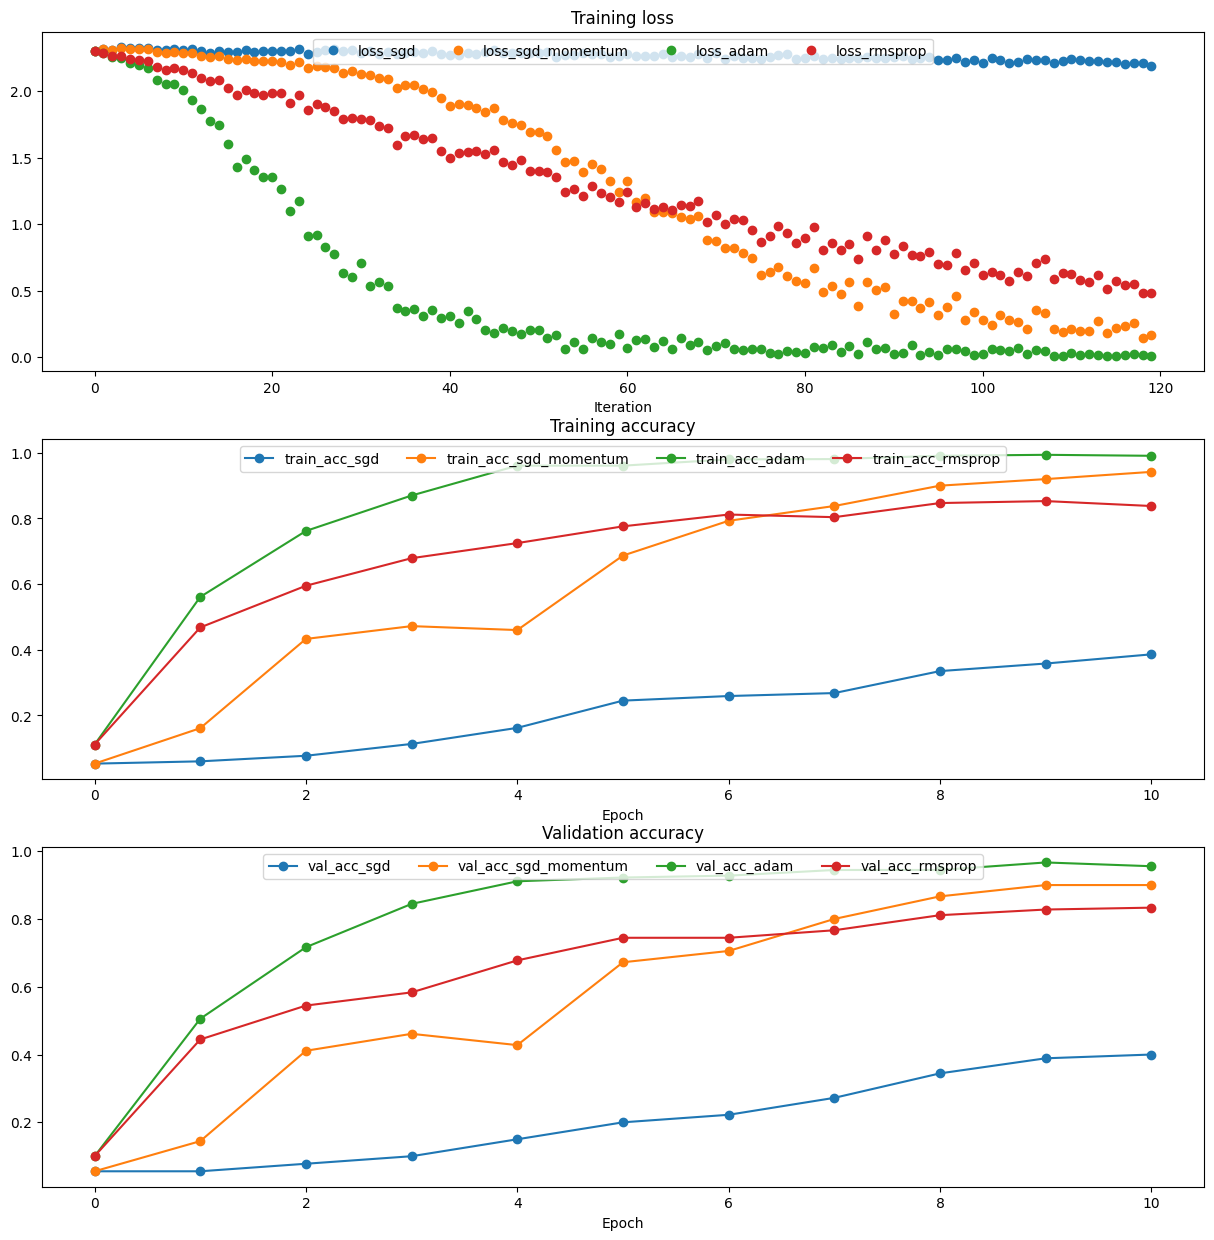

sgd           final loss (среднее за последние 10 итераций): 2.2173   best val acc: 0.4000
sgd_momentum  final loss (среднее за последние 10 итераций): 0.2064   best val acc: 0.9000
adam          final loss (среднее за последние 10 итераций): 0.0169   best val acc: 0.9667
rmsprop       final loss (среднее за последние 10 итераций): 0.5519   best val acc: 0.8333


In [32]:
learning_rates = {'rmsprop': 1e-4, 'adam': 1e-3}
for update_rule in ['adam', 'rmsprop']:
    print('running with ', update_rule)
    np.random.seed(231)
    model = FullyConnectedNet([100, 100, 100, 100, 100], weight_scale=1e-1)

    solver = Solver(model, small_data,
                    num_epochs=10, batch_size=100,
                    update_rule=update_rule,
                    optim_config={
                      'learning_rate': learning_rates[update_rule]
                    },
                    verbose=True, print_every=40)
    solvers[update_rule] = solver
    solver.train()
    print()

plot_solvers(solvers)

for name, s in solvers.items():
    print('%-13s final loss (среднее за последние 10 итераций): %.4f   best val acc: %.4f'
          % (name, np.mean(s.loss_history[-10:]), s.best_val_acc))

Сравнение четырех методов (одинаковая 6-слойная сеть, 10 эпох): Adam - лучшая val accuracy 96.7% и самый низкий loss, SGD + momentum - 90%, RMSProp (lr = 1e-4) - 83%, обычный SGD - 40%. Адаптивные методы подбирают свой шаг для каждого параметра и сходятся быстрее; Adam сочетает идеи импульса и RMSProp, поэтому работает лучше всех. RMSProp с шагом 1e-4 медленнее Adam с шагом 1e-3 в основном из-за меньшего шага.

# Нормализация по мини-батчам

Идея нормализации по мини-батчам предложена в работе [1]

[1] Sergey Ioffe and Christian Szegedy, "Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift", ICML 2015.

Прямой проход для слоя батч-нормализации - `batchnorm_forward`.

В режиме обучения признаки нормируются по статистикам текущего батча, параллельно накапливаются бегущие среднее и дисперсия:
running_mean = momentum * running_mean + (1 - momentum) * sample_mean. В режиме теста используются накопленные значения.

In [33]:
def batchnorm_forward(x, gamma, beta, bn_param):
    """
    x: (N, D), gamma, beta: (D,)
    bn_param: mode ('train' / 'test'), eps, momentum, running_mean, running_var
    """
    mode = bn_param['mode']
    eps = bn_param.get('eps', 1e-5)
    momentum = bn_param.get('momentum', 0.9)

    N, D = x.shape
    running_mean = bn_param.get('running_mean', np.zeros(D, dtype=x.dtype))
    running_var = bn_param.get('running_var', np.zeros(D, dtype=x.dtype))

    if mode == 'train':
        sample_mean = x.mean(axis=0)
        sample_var = x.var(axis=0)
        std = np.sqrt(sample_var + eps)
        x_hat = (x - sample_mean) / std
        out = gamma * x_hat + beta
        cache = (x_hat, gamma, std)

        running_mean = momentum * running_mean + (1 - momentum) * sample_mean
        running_var = momentum * running_var + (1 - momentum) * sample_var
    elif mode == 'test':
        x_hat = (x - running_mean) / np.sqrt(running_var + eps)
        out = gamma * x_hat + beta
        cache = None
    else:
        raise ValueError('Invalid forward batchnorm mode "%s"' % mode)

    bn_param['running_mean'] = running_mean
    bn_param['running_var'] = running_var
    return out, cache

In [34]:
# проверка в режиме обучения: средние и дисперсии признаков до и после нормализации
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
X = np.random.randn(N, D1)
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)
a = np.maximum(0, X.dot(W1)).dot(W2)

print('Before batch normalization:')
print_mean_std(a, axis=0)

gamma = np.ones((D3,))
beta = np.zeros((D3,))
# средние около 0, std около 1
print('After batch normalization (gamma=1, beta=0)')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm, axis=0)

gamma = np.asarray([1.0, 2.0, 3.0])
beta = np.asarray([11.0, 12.0, 13.0])
# средние около beta, std около gamma
print('After batch normalization (gamma=', gamma, ', beta=', beta, ')')
a_norm, _ = batchnorm_forward(a, gamma, beta, {'mode': 'train'})
print_mean_std(a_norm, axis=0)

Before batch normalization:
  means:  [ -2.3814598  -13.18038246   1.91780462]
  stds:   [27.18502186 34.21455511 37.68611762]

After batch normalization (gamma=1, beta=0)
  means:  [ 5.32907052e-17  3.44169138e-17 -8.18789481e-18]
  stds:   [0.99999999 1.         1.        ]

After batch normalization (gamma= [1. 2. 3.] , beta= [11. 12. 13.] )
  means:  [11. 12. 13.]
  stds:   [0.99999999 1.99999999 2.99999999]



In [35]:
# проверка режима теста: сначала прогреваем бегущие средние, потом один проход в режиме test
np.random.seed(231)
N, D1, D2, D3 = 200, 50, 60, 3
W1 = np.random.randn(D1, D2)
W2 = np.random.randn(D2, D3)

bn_param = {'mode': 'train'}
gamma = np.ones(D3)
beta = np.zeros(D3)

for t in range(50):
    X = np.random.randn(N, D1)
    a = np.maximum(0, X.dot(W1)).dot(W2)
    batchnorm_forward(a, gamma, beta, bn_param)

bn_param['mode'] = 'test'
X = np.random.randn(N, D1)
a = np.maximum(0, X.dot(W1)).dot(W2)
a_norm, _ = batchnorm_forward(a, gamma, beta, bn_param)

# средние около 0, std около 1, но с большим шумом, чем в режиме обучения
print('After batch normalization (test-time):')
print_mean_std(a_norm, axis=0)

After batch normalization (test-time):
  means:  [-0.03927354 -0.04349152 -0.10452688]
  stds:   [1.01531428 1.01238373 0.97819988]



Обратный проход - `batchnorm_backward`. Используется упрощенная формула, полученная из вычислительного графа:

$dx = \frac{1}{N\sigma}\left(N\,d\hat x - \sum d\hat x - \hat x \sum (d\hat x \cdot \hat x)\right)$, где $d\hat x = dout \cdot \gamma$.

In [36]:
def batchnorm_backward(dout, cache):
    x_hat, gamma, std = cache
    N = dout.shape[0]

    dbeta = np.sum(dout, axis=0)
    dgamma = np.sum(dout * x_hat, axis=0)

    dx_hat = dout * gamma
    dx = (N * dx_hat - np.sum(dx_hat, axis=0)
          - x_hat * np.sum(dx_hat * x_hat, axis=0)) / (N * std)
    return dx, dgamma, dbeta


def affine_bn_relu_forward(x, w, b, gamma, beta, bn_param):
    a, fc_cache = affine_forward(x, w, b)
    an, bn_cache = batchnorm_forward(a, gamma, beta, bn_param)
    out, relu_cache = relu_forward(an)
    return out, (fc_cache, bn_cache, relu_cache)


def affine_bn_relu_backward(dout, cache):
    fc_cache, bn_cache, relu_cache = cache
    dan = relu_backward(dout, relu_cache)
    da, dgamma, dbeta = batchnorm_backward(dan, bn_cache)
    dx, dw, db = affine_backward(da, fc_cache)
    return dx, dw, db, dgamma, dbeta

In [37]:
# Gradient check batchnorm backward pass
np.random.seed(231)
N, D = 4, 5
x = 5 * np.random.randn(N, D) + 12
gamma = np.random.randn(D)
beta = np.random.randn(D)
dout = np.random.randn(N, D)

bn_param = {'mode': 'train'}
fx = lambda x: batchnorm_forward(x, gamma, beta, bn_param)[0]
fg = lambda a: batchnorm_forward(x, a, beta, bn_param)[0]
fb = lambda b: batchnorm_forward(x, gamma, b, bn_param)[0]

dx_num = eval_numerical_gradient_array(fx, x, dout)
da_num = eval_numerical_gradient_array(fg, gamma.copy(), dout)
db_num = eval_numerical_gradient_array(fb, beta.copy(), dout)

_, cache = batchnorm_forward(x, gamma, beta, bn_param)
dx, dgamma, dbeta = batchnorm_backward(dout, cache)
# ошибки от 1e-13 до 1e-8
print('dx error: ', rel_error(dx_num, dx))
print('dgamma error: ', rel_error(da_num, dgamma))
print('dbeta error: ', rel_error(db_num, dbeta))

dx error:  1.7029226384366253e-09
dgamma error:  7.420414216247087e-13
dbeta error:  2.8795057655839487e-12


Класс FullyConnectedNet уже поддерживает батч-нормализацию (normalization='batchnorm'): слой нормализации ставится перед каждой ReLU, кроме выхода сети. Проверка градиентов:

In [38]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for reg in [0, 3.14]:
    print('Running check with reg = ', reg)
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                              reg=reg, weight_scale=5e-2, dtype=np.float64,
                              normalization='batchnorm')

    loss, grads = model.loss(X, y)
    print('Initial loss: ', loss)

    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
    if reg == 0: print()

Running check with reg =  0
Initial loss:  2.2611955101340957


W1 relative error: 1.10e-04


W2 relative error: 2.85e-06


W3 relative error: 4.05e-10
b1 relative error: 2.22e-07
b2 relative error: 2.22e-08
b3 relative error: 1.01e-10
beta1 relative error: 7.33e-09
beta2 relative error: 1.89e-09


gamma1 relative error: 6.96e-09
gamma2 relative error: 1.96e-09

Running check with reg =  3.14
Initial loss:  6.996533220108303


W1 relative error: 1.98e-06


W2 relative error: 2.28e-06


W3 relative error: 1.11e-08
b1 relative error: 1.38e-08
b2 relative error: 7.99e-07
b3 relative error: 1.73e-10
beta1 relative error: 6.65e-09


beta2 relative error: 3.48e-09
gamma1 relative error: 8.80e-09
gamma2 relative error: 5.28e-09


Обучение 6-слойной сети на наборе из 1000 изображений с батч-нормализацией и без нее.

In [39]:
np.random.seed(231)
hidden_dims = [100, 100, 100, 100, 100]

num_train = 1000
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

weight_scale = 2e-2
bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization='batchnorm')
model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)

print('Solver with batch norm:')
bn_solver = Solver(bn_model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=40)
bn_solver.train()

print('\nSolver without batch norm:')
solver = Solver(model, small_data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=40)
solver.train()

Solver with batch norm:
(Iteration 1 / 200) loss: 2.347180
(Epoch 0 / 10) train acc: 0.239000; val_acc: 0.233333


(Epoch 1 / 10) train acc: 0.890000; val_acc: 0.827778


(Epoch 2 / 10) train acc: 0.968000; val_acc: 0.966667
(Iteration 41 / 200) loss: 0.585541


(Epoch 3 / 10) train acc: 0.991000; val_acc: 0.950000


(Epoch 4 / 10) train acc: 0.991000; val_acc: 0.950000
(Iteration 81 / 200) loss: 0.150612


...

(Epoch 3 / 10) train acc: 0.259000; val_acc: 0.227778
(Epoch 4 / 10) train acc: 0.311000; val_acc: 0.283333
(Iteration 81 / 200) loss: 1.375617


(Epoch 5 / 10) train acc: 0.391000; val_acc: 0.377778
(Epoch 6 / 10) train acc: 0.633000; val_acc: 0.588889


(Iteration 121 / 200) loss: 0.977268
(Epoch 7 / 10) train acc: 0.612000; val_acc: 0.588889


(Epoch 8 / 10) train acc: 0.757000; val_acc: 0.738889
(Iteration 161 / 200) loss: 0.605695


(Epoch 9 / 10) train acc: 0.870000; val_acc: 0.811111
(Epoch 10 / 10) train acc: 0.925000; val_acc: 0.850000


Графики обучения двух сетей.

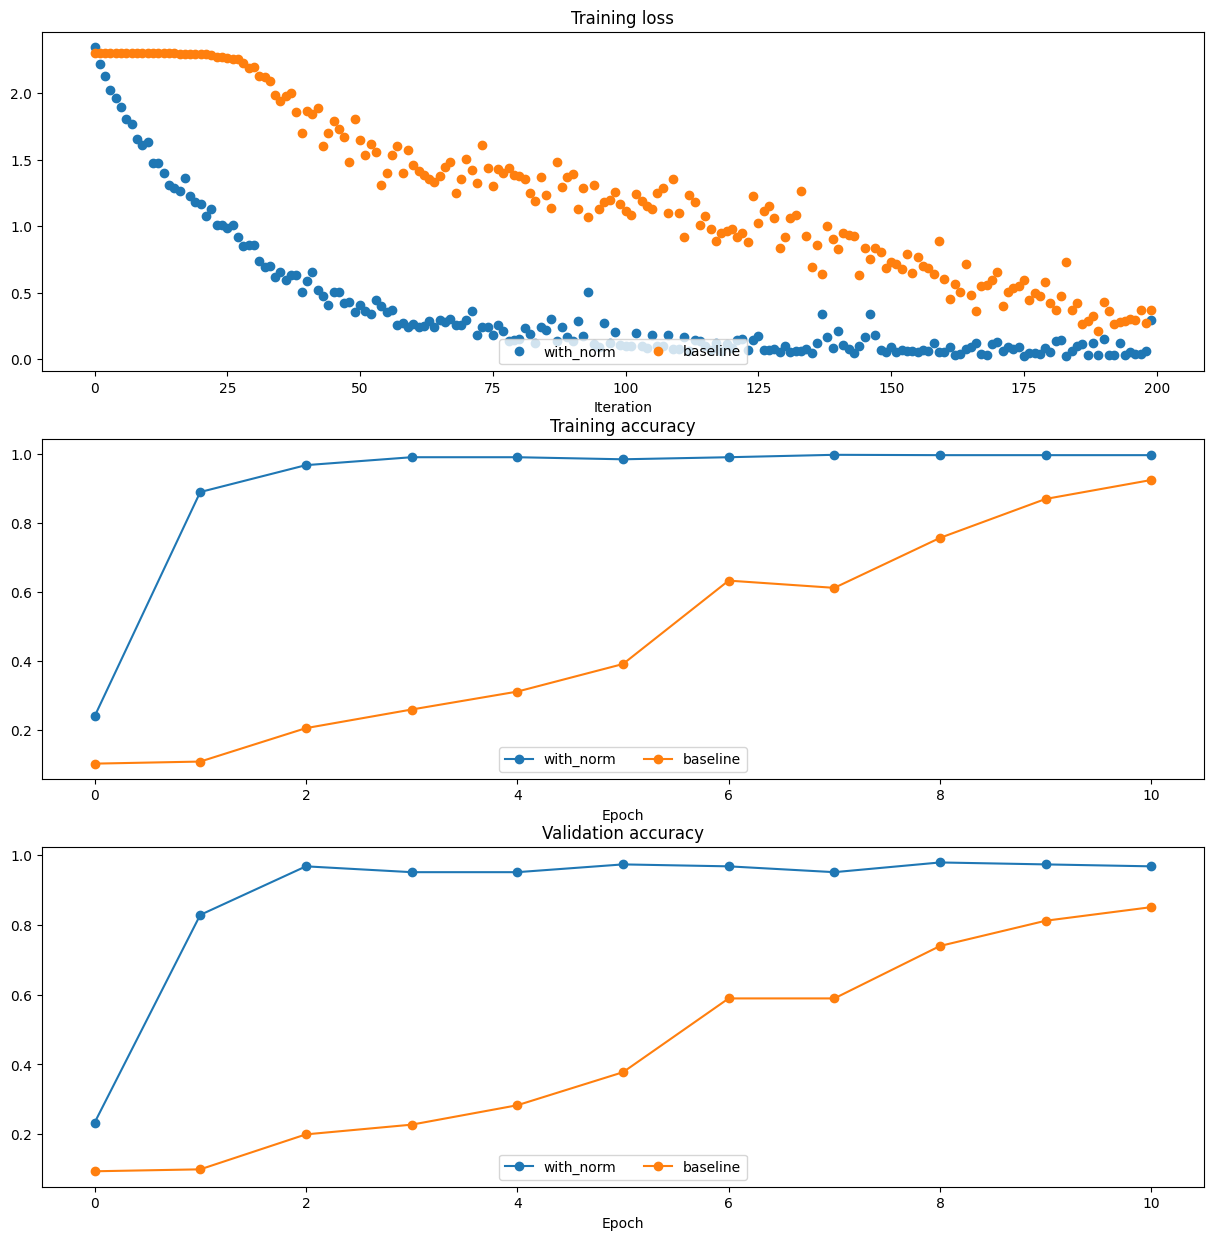

In [40]:
def plot_training_history(title, label, baseline, bn_solvers, plot_fn, bl_marker='.', bn_marker='.', labels=None):
    """графики обучения: сети с нормализацией против базовой"""
    plt.title(title)
    plt.xlabel(label)
    bn_plots = [plot_fn(bn_solver) for bn_solver in bn_solvers]
    bl_plot = plot_fn(baseline)
    num_bn = len(bn_plots)
    for i in range(num_bn):
        label = 'with_norm'
        if labels is not None:
            label += str(labels[i])
        plt.plot(bn_plots[i], bn_marker, label=label)
    label = 'baseline'
    if labels is not None:
        label += str(labels[0])
    plt.plot(bl_plot, bl_marker, label=label)
    plt.legend(loc='lower center', ncol=num_bn + 1)


plt.subplot(3, 1, 1)
plot_training_history('Training loss', 'Iteration', solver, [bn_solver],
                      lambda x: x.loss_history, bl_marker='o', bn_marker='o')
plt.subplot(3, 1, 2)
plot_training_history('Training accuracy', 'Epoch', solver, [bn_solver],
                      lambda x: x.train_acc_history, bl_marker='-o', bn_marker='-o')
plt.subplot(3, 1, 3)
plot_training_history('Validation accuracy', 'Epoch', solver, [bn_solver],
                      lambda x: x.val_acc_history, bl_marker='-o', bn_marker='-o')

plt.gcf().set_size_inches(15, 15)
plt.show()

**Выводы:** батч-нормализация значительно ускоряет сходимость. Сеть с BN уже после 2 эпох имеет val accuracy ~97%, а сеть без BN за это время только начинает учиться (20%) и к 10-й эпохе достигает лишь 85%. BN нормирует входы каждого слоя, поэтому градиенты не затухают и не взрываются в глубокой сети, обучение меньше зависит от инициализации и можно использовать больший шаг.

Обучение 6-слойной сети с батч-нормализацией и без нее при разных размерах батча.

In [41]:
def run_batchsize_experiments(normalization_mode):
    np.random.seed(231)
    hidden_dims = [100, 100, 100, 100, 100]
    num_train = 1000
    small_data = {
      'X_train': data['X_train'][:num_train],
      'y_train': data['y_train'][:num_train],
      'X_val': data['X_val'],
      'y_val': data['y_val'],
    }
    n_epochs = 10
    weight_scale = 2e-2
    batch_sizes = [5, 10, 50]
    lr = 10**(-3.5)
    solver_bsize = batch_sizes[0]

    print('No normalization: batch size = ', solver_bsize)
    model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=None)
    solver = Solver(model, small_data,
                    num_epochs=n_epochs, batch_size=solver_bsize,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': lr,
                    },
                    verbose=False)
    solver.train()

    bn_solvers = []
    for i in range(len(batch_sizes)):
        b_size = batch_sizes[i]
        print('Normalization: batch size = ', b_size)
        bn_model = FullyConnectedNet(hidden_dims, weight_scale=weight_scale, normalization=normalization_mode)
        bn_solver = Solver(bn_model, small_data,
                        num_epochs=n_epochs, batch_size=b_size,
                        update_rule='adam',
                        optim_config={
                          'learning_rate': lr,
                        },
                        verbose=False)
        bn_solver.train()
        bn_solvers.append(bn_solver)

    return bn_solvers, solver, batch_sizes

batch_sizes = [5, 10, 50]
bn_solvers_bsize, solver_bsize, batch_sizes = run_batchsize_experiments('batchnorm')

No normalization: batch size =  5


Normalization: batch size =  5


Normalization: batch size =  10


Normalization: batch size =  50


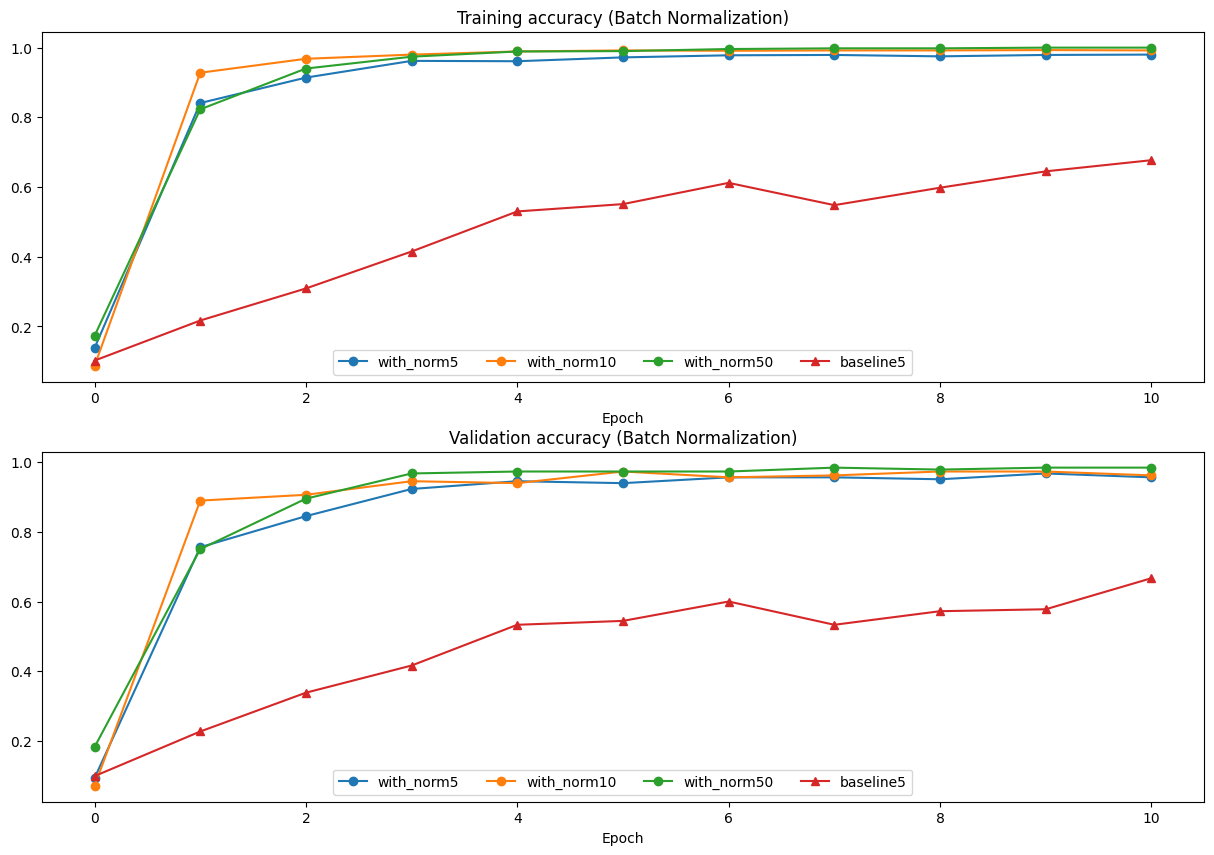

baseline (без BN), batch 5: best val acc 0.6667
batchnorm, batch  5: best val acc 0.9667, final train acc 0.9800
batchnorm, batch 10: best val acc 0.9722, final train acc 0.9920
batchnorm, batch 50: best val acc 0.9833, final train acc 1.0000


In [42]:
plt.subplot(2, 1, 1)
plot_training_history('Training accuracy (Batch Normalization)', 'Epoch', solver_bsize, bn_solvers_bsize,
                      lambda x: x.train_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)
plt.subplot(2, 1, 2)
plot_training_history('Validation accuracy (Batch Normalization)', 'Epoch', solver_bsize, bn_solvers_bsize,
                      lambda x: x.val_acc_history, bl_marker='-^', bn_marker='-o', labels=batch_sizes)

plt.gcf().set_size_inches(15, 10)
plt.show()

print('baseline (без BN), batch 5: best val acc %.4f' % solver_bsize.best_val_acc)
for bs, s in zip(batch_sizes, bn_solvers_bsize):
    print('batchnorm, batch %2d: best val acc %.4f, final train acc %.4f' % (bs, s.best_val_acc, s.train_acc_history[-1]))

**Выводы:** при всех размерах батча сеть с BN работает намного лучше базовой (лучшая val accuracy 96.7-98.3% против 66.7% без нормализации). С увеличением размера батча качество с BN растет (5 -> 96.7%, 10 -> 97.2%, 50 -> 98.3%): при маленьком батче среднее и дисперсия, по которым идет нормализация, оцениваются по нескольким объектам и сильно шумят, а также сильнее отличаются от бегущих средних, используемых на тесте. Поэтому эффективность батч-нормализации зависит от размера батча.

# Dropout

Прямой проход для dropout-слоя. Используется inverted dropout: параметр p - вероятность сохранить нейрон, на этапе обучения выход делится на p, поэтому на этапе теста слой ничего не делает.

http://cs231n.github.io/neural-networks-2/#reg

In [43]:
def dropout_forward(x, dropout_param):
    """
    dropout_param: p - вероятность сохранить нейрон, mode - 'train' / 'test',
    seed - для воспроизводимости (нужен при проверке градиента)
    """
    p, mode = dropout_param['p'], dropout_param['mode']
    if 'seed' in dropout_param:
        np.random.seed(dropout_param['seed'])

    mask = None
    if mode == 'train':
        mask = (np.random.rand(*x.shape) < p) / p
        out = x * mask
    elif mode == 'test':
        out = x

    cache = (dropout_param, mask)
    out = out.astype(x.dtype, copy=False)
    return out, cache

In [44]:
np.random.seed(231)
x = np.random.randn(500, 500) + 10

for p in [0.25, 0.4, 0.7]:
    out, _ = dropout_forward(x, {'mode': 'train', 'p': p})
    out_test, _ = dropout_forward(x, {'mode': 'test', 'p': p})

    print('Running tests with p = ', p)
    print('Mean of input: ', x.mean())
    print('Mean of train-time output: ', out.mean())
    print('Mean of test-time output: ', out_test.mean())
    print('Fraction of train-time output set to zero: ', (out == 0).mean())
    print('Fraction of test-time output set to zero: ', (out_test == 0).mean())
    print()

Running tests with p =  0.25
Mean of input:  10.000207878477502
Mean of train-time output:  10.014059116977283
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.749784
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.4
Mean of input:  10.000207878477502
Mean of train-time output:  9.977917658761159
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.600796
Fraction of test-time output set to zero:  0.0

Running tests with p =  0.7
Mean of input:  10.000207878477502
Mean of train-time output:  9.987811912159426
Mean of test-time output:  10.000207878477502
Fraction of train-time output set to zero:  0.30074
Fraction of test-time output set to zero:  0.0



Обратный проход для dropout-слоя.

In [45]:
def dropout_backward(dout, cache):
    dropout_param, mask = cache
    mode = dropout_param['mode']
    if mode == 'train':
        dx = dout * mask
    elif mode == 'test':
        dx = dout
    return dx

In [46]:
np.random.seed(231)
x = np.random.randn(10, 10) + 10
dout = np.random.randn(*x.shape)

dropout_param = {'mode': 'train', 'p': 0.2, 'seed': 123}
out, cache = dropout_forward(x, dropout_param)
dx = dropout_backward(dout, cache)
dx_num = eval_numerical_gradient_array(lambda xx: dropout_forward(xx, dropout_param)[0], x, dout)

# ошибка порядка e-10 или меньше
print('dx relative error: ', rel_error(dx, dx_num))

dx relative error: 

 5.44560814873387e-11


FullyConnectedNet поддерживает dropout: при dropout != 1 после каждой ReLU добавляется dropout-слой. Проверка:

In [47]:
np.random.seed(231)
N, D, H1, H2, C = 2, 15, 20, 30, 10
X = np.random.randn(N, D)
y = np.random.randint(C, size=(N,))

for dropout in [1, 0.75, 0.5]:
    print('Running check with dropout = ', dropout)
    model = FullyConnectedNet([H1, H2], input_dim=D, num_classes=C,
                              weight_scale=5e-2, dtype=np.float64,
                              dropout=dropout, seed=123)

    loss, grads = model.loss(X, y)
    print('Initial loss: ', loss)

    # ошибки порядка e-6 и меньше
    for name in sorted(grads):
        f = lambda _: model.loss(X, y)[0]
        grad_num = eval_numerical_gradient(f, model.params[name], verbose=False, h=1e-5)
        print('%s relative error: %.2e' % (name, rel_error(grad_num, grads[name])))
    print()

Running check with dropout =  1
Initial loss:  2.3004790897684924


W1 relative error: 1.48e-07


W2 relative error: 2.21e-05


W3 relative error: 3.53e-07
b1 relative error: 5.38e-09
b2 relative error: 2.09e-09
b3 relative error: 5.80e-11

Running check with dropout =  0.75
Initial loss:  2.302371489704412


W1 relative error: 1.90e-07


W2 relative error: 4.76e-06


W3 relative error: 2.60e-08
b1 relative error: 4.73e-09
b2 relative error: 1.82e-09
b3 relative error: 1.70e-10

Running check with dropout =  0.5
Initial loss:  2.3042759220785896


W1 relative error: 3.11e-07


W2 relative error: 1.84e-08


W3 relative error: 5.35e-08
b1 relative error: 5.37e-09
b2 relative error: 2.99e-09
b3 relative error: 1.13e-10



Две двухслойные сети с dropout-слоем и без на наборе из 500 изображений. По заданию вероятность отсева 0.25, то есть p (вероятность сохранить нейрон) = 0.75. Для сравнения добавлен вариант с сильным dropout (p = 0.25).

In [48]:
np.random.seed(231)
num_train = 500
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

solvers = {}
dropout_choices = [1, 0.75, 0.25]
for dropout in dropout_choices:
    model = FullyConnectedNet([500], dropout=dropout)
    print(dropout)

    solver = Solver(model, small_data,
                    num_epochs=25, batch_size=100,
                    update_rule='adam',
                    optim_config={
                      'learning_rate': 5e-4,
                    },
                    verbose=True, print_every=100)
    solver.train()
    solvers[dropout] = solver
    print()

1
(Iteration 1 / 125) loss: 2.304417
(Epoch 0 / 25) train acc: 0.484000; val_acc: 0.394444
(Epoch 1 / 25) train acc: 0.848000; val_acc: 0.772222
(Epoch 2 / 25) train acc: 0.872000; val_acc: 0.794444
(Epoch 3 / 25) train acc: 0.864000; val_acc: 0.794444
(Epoch 4 / 25) train acc: 0.860000; val_acc: 0.783333


(Epoch 5 / 25) train acc: 0.856000; val_acc: 0.777778
(Epoch 6 / 25) train acc: 0.848000; val_acc: 0.766667
(Epoch 7 / 25) train acc: 0.844000; val_acc: 0.761111


(Epoch 8 / 25) train acc: 0.836000; val_acc: 0.766667
(Epoch 9 / 25) train acc: 0.834000; val_acc: 0.772222
(Epoch 10 / 25) train acc: 0.850000; val_acc: 0.777778
(Epoch 11 / 25) train acc: 0.858000; val_acc: 0.777778


(Epoch 12 / 25) train acc: 0.868000; val_acc: 0.794444
(Epoch 13 / 25) train acc: 0.878000; val_acc: 0.800000
(Epoch 14 / 25) train acc: 0.886000; val_acc: 0.805556
(Epoch 15 / 25) train acc: 0.898000; val_acc: 0.816667


(Epoch 16 / 25) train acc: 0.906000; val_acc: 0.822222
(Epoch 17 / 25) train acc: 0.922000; val_acc: 0.833333
(Epoch 18 / 25) train acc: 0.932000; val_acc: 0.838889
(Epoch 19 / 25) train acc: 0.934000; val_acc: 0.872222


...

(Epoch 22 / 25) train acc: 0.952000; val_acc: 0.877778
(Epoch 23 / 25) train acc: 0.952000; val_acc: 0.900000
(Epoch 24 / 25) train acc: 0.956000; val_acc: 0.911111
(Epoch 25 / 25) train acc: 0.958000; val_acc: 0.911111

0.25
(Iteration 1 / 125) loss: 2.304624
(Epoch 0 / 25) train acc: 0.266000; val_acc: 0.200000
(Epoch 1 / 25) train acc: 0.808000; val_acc: 0.722222
(Epoch 2 / 25) train acc: 0.858000; val_acc: 0.772222


(Epoch 3 / 25) train acc: 0.856000; val_acc: 0.772222
(Epoch 4 / 25) train acc: 0.848000; val_acc: 0.794444
(Epoch 5 / 25) train acc: 0.840000; val_acc: 0.788889
(Epoch 6 / 25) train acc: 0.838000; val_acc: 0.788889
(Epoch 7 / 25) train acc: 0.838000; val_acc: 0.783333
(Epoch 8 / 25) train acc: 0.834000; val_acc: 0.777778


(Epoch 9 / 25) train acc: 0.844000; val_acc: 0.777778
(Epoch 10 / 25) train acc: 0.850000; val_acc: 0.788889
(Epoch 11 / 25) train acc: 0.852000; val_acc: 0.783333
(Epoch 12 / 25) train acc: 0.860000; val_acc: 0.783333
(Epoch 13 / 25) train acc: 0.862000; val_acc: 0.783333


(Epoch 14 / 25) train acc: 0.866000; val_acc: 0.783333
(Epoch 15 / 25) train acc: 0.868000; val_acc: 0.788889
(Epoch 16 / 25) train acc: 0.876000; val_acc: 0.811111
(Epoch 17 / 25) train acc: 0.878000; val_acc: 0.800000
(Epoch 18 / 25) train acc: 0.886000; val_acc: 0.805556
(Epoch 19 / 25) train acc: 0.892000; val_acc: 0.811111


(Epoch 20 / 25) train acc: 0.902000; val_acc: 0.822222
(Iteration 101 / 125) loss: 0.454172
(Epoch 21 / 25) train acc: 0.908000; val_acc: 0.827778
(Epoch 22 / 25) train acc: 0.914000; val_acc: 0.827778
(Epoch 23 / 25) train acc: 0.924000; val_acc: 0.838889
(Epoch 24 / 25) train acc: 0.926000; val_acc: 0.844444
(Epoch 25 / 25) train acc: 0.930000; val_acc: 0.866667



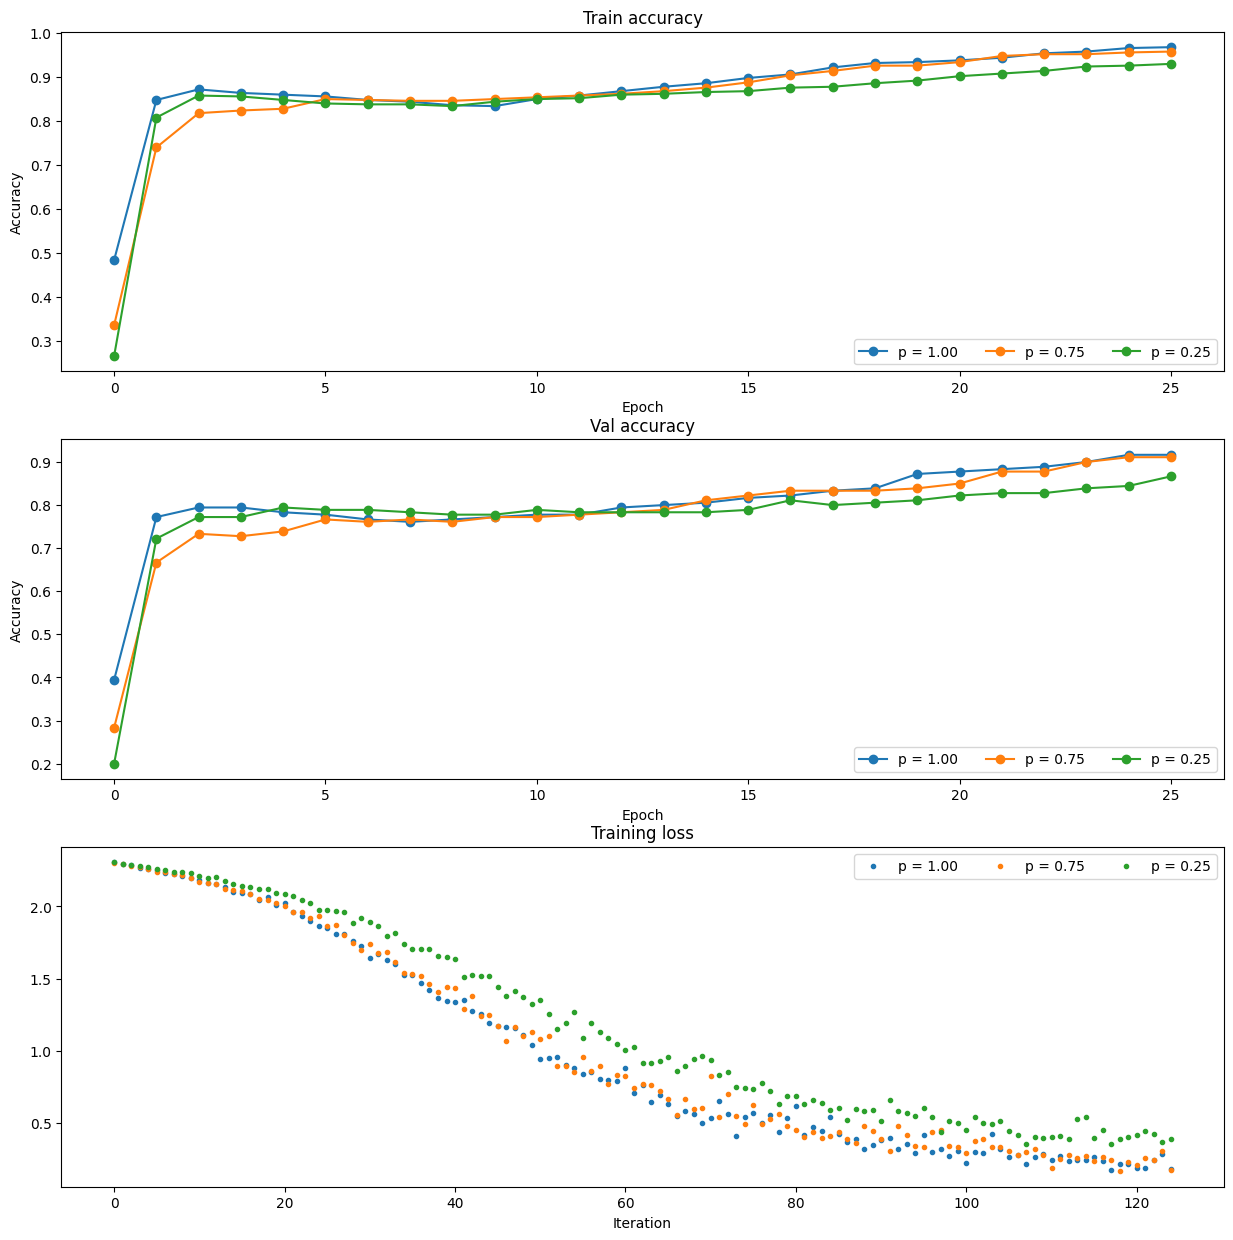

p = 1.00: final train acc 0.9680, final val acc 0.9167, best val acc 0.9167
p = 0.75: final train acc 0.9580, final val acc 0.9111, best val acc 0.9111
p = 0.25: final train acc 0.9300, final val acc 0.8667, best val acc 0.8667


In [49]:
train_accs = []
val_accs = []
for dropout in dropout_choices:
    solver = solvers[dropout]
    train_accs.append(solver.train_acc_history[-1])
    val_accs.append(solver.val_acc_history[-1])

plt.subplot(3, 1, 1)
for dropout in dropout_choices:
    plt.plot(solvers[dropout].train_acc_history, 'o-', label='p = %.2f' % dropout)
plt.title('Train accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=3, loc='lower right')

plt.subplot(3, 1, 2)
for dropout in dropout_choices:
    plt.plot(solvers[dropout].val_acc_history, 'o-', label='p = %.2f' % dropout)
plt.title('Val accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(ncol=3, loc='lower right')

plt.subplot(3, 1, 3)
for dropout in dropout_choices:
    plt.plot(solvers[dropout].loss_history, '.', label='p = %.2f' % dropout)
plt.title('Training loss')
plt.xlabel('Iteration')
plt.legend(ncol=3, loc='upper right')

plt.gcf().set_size_inches(15, 15)
plt.show()

for dropout in dropout_choices:
    s = solvers[dropout]
    print('p = %.2f: final train acc %.4f, final val acc %.4f, best val acc %.4f'
          % (dropout, s.train_acc_history[-1], s.val_acc_history[-1], s.best_val_acc))

**Выводы:** на нашем наборе dropout почти не дал выигрыша: без dropout val accuracy 91.7%, с p = 0.75 (отсев 25%) - 91.1%, с сильным dropout p = 0.25 - 86.7%. При этом с dropout разрыв между train и val меньше, а обучение идет медленнее (сети нужно больше эпох, потому что на каждой итерации работает только часть нейронов). За 25 эпох сеть с сильным dropout не успела выйти на плато. Dropout - это регуляризация, и он полезен, когда модель сильно переобучается; здесь простая сеть на 500 изображениях MNIST 8x8 переобучается не так сильно, поэтому заметного эффекта нет.

Лучшая полносвязная сеть для нашего набора данных (для CIFAR-10 требуется не ниже 50% на валидации; на MNIST ориентируемся на максимально возможную точность). Раздел перенесен сюда, после реализации батч-нормализации и dropout, так как в лучшей модели используются оба приема. Для выбора конфигурации проводится небольшой перебор.

In [50]:
best_model = None
best_val = -1
configs = [
    # (hidden_dims, normalization, dropout, reg, lr)
    ([100, 100], None, 1, 1e-3, 1e-3),
    ([256, 256], None, 1, 1e-3, 1e-3),
    ([256, 256], 'batchnorm', 1, 1e-3, 1e-3),
    ([256, 256], 'batchnorm', 0.75, 1e-3, 1e-3),
    ([256, 128, 64], 'batchnorm', 0.75, 1e-3, 1e-3),
    ([512, 256], 'batchnorm', 0.5, 1e-4, 1e-3),
]

fc_results = []
for hidden_dims, norm, dp, reg, lr in configs:
    np.random.seed(0)
    model = FullyConnectedNet(hidden_dims, weight_scale=5e-2, normalization=norm,
                              dropout=dp, reg=reg)
    solver = Solver(model, data, num_epochs=30, batch_size=100,
                    update_rule='adam', optim_config={'learning_rate': lr},
                    lr_decay=0.95, verbose=False, num_train_samples=None)
    solver.train()
    fc_results.append((hidden_dims, norm, dp, reg, solver.best_val_acc))
    print('hidden %-15s norm %-9s dropout %.2f reg %.0e -> best val acc %.4f'
          % (hidden_dims, norm, dp, reg, solver.best_val_acc))
    if solver.best_val_acc > best_val:
        best_val = solver.best_val_acc
        best_model = model
        best_solver = solver

print('\nЛучшая val accuracy: %.4f' % best_val)

hidden [100, 100]      norm None      dropout 1.00 reg 1e-03 -> best val acc 0.9722


hidden [256, 256]      norm None      dropout 1.00 reg 1e-03 -> best val acc 0.9778


hidden [256, 256]      norm batchnorm dropout 1.00 reg 1e-03 -> best val acc 0.9889


hidden [256, 256]      norm batchnorm dropout 0.75 reg 1e-03 -> best val acc 0.9833


hidden [256, 128, 64]  norm batchnorm dropout 0.75 reg 1e-03 -> best val acc 0.9889


hidden [512, 256]      norm batchnorm dropout 0.50 reg 1e-04 -> best val acc 0.9889

Лучшая val accuracy: 0.9889


Accuracy лучшей модели на валидационной и тестовой выборках.

In [51]:
y_test_pred = np.argmax(best_model.loss(data['X_test']), axis=1)
y_val_pred = np.argmax(best_model.loss(data['X_val']), axis=1)
print('Validation set accuracy: ', (y_val_pred == data['y_val']).mean())
print('Test set accuracy: ', (y_test_pred == data['y_test']).mean())

Validation set accuracy:  0.9888888888888889
Test set accuracy:  0.9805555555555555


# Сверточные нейронные сети (CNN)

Прямой проход для сверточного слоя - `conv_forward_naive`. Цикл идет по позициям окна свертки, внутри позиции свертка для всех изображений и фильтров считается одним матричным умножением.

In [52]:
def conv_forward_naive(x, w, b, conv_param):
    """
    x: (N, C, H, W), w: (F, C, HH, WW), b: (F,)
    conv_param: stride, pad
    out: (N, F, H', W'), H' = 1 + (H + 2 * pad - HH) / stride
    """
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']
    H_out = 1 + (H + 2 * pad - HH) // stride
    W_out = 1 + (W + 2 * pad - WW) // stride

    x_pad = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)), mode='constant')
    w_flat = w.reshape(F, -1)
    out = np.zeros((N, F, H_out, W_out), dtype=x.dtype)

    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            patch = x_pad[:, :, hs:hs + HH, ws:ws + WW].reshape(N, -1)  # (N, C*HH*WW)
            out[:, :, i, j] = patch.dot(w_flat.T) + b

    cache = (x, w, b, conv_param)
    return out, cache

In [53]:
x_shape = (2, 3, 4, 4)
w_shape = (3, 3, 4, 4)
x = np.linspace(-0.1, 0.5, num=np.prod(x_shape)).reshape(x_shape)
w = np.linspace(-0.2, 0.3, num=np.prod(w_shape)).reshape(w_shape)
b = np.linspace(-0.1, 0.2, num=3)

conv_param = {'stride': 2, 'pad': 1}
out, _ = conv_forward_naive(x, w, b, conv_param)
correct_out = np.array([[[[-0.08759809, -0.10987781],
                           [-0.18387192, -0.2109216 ]],
                          [[ 0.21027089,  0.21661097],
                           [ 0.22847626,  0.23004637]],
                          [[ 0.50813986,  0.54309974],
                           [ 0.64082444,  0.67101435]]],
                         [[[-0.98053589, -1.03143541],
                           [-1.19128892, -1.24695841]],
                          [[ 0.69108355,  0.66880383],
                           [ 0.59480972,  0.56776003]],
                          [[ 2.36270298,  2.36904306],
                           [ 2.38090835,  2.38247847]]]])

# ошибка порядка e-8
print('Testing conv_forward_naive')
print('difference: ', rel_error(out, correct_out))

Testing conv_forward_naive
difference:  2.2121476575931688e-08


Обратный проход - `conv_backward_naive`.

In [54]:
def conv_backward_naive(dout, cache):
    x, w, b, conv_param = cache
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']
    _, _, H_out, W_out = dout.shape

    x_pad = np.pad(x, ((0, 0), (0, 0), (pad, pad), (pad, pad)), mode='constant')
    dx_pad = np.zeros_like(x_pad)
    w_flat = w.reshape(F, -1)
    dw_flat = np.zeros_like(w_flat)
    db = np.sum(dout, axis=(0, 2, 3))

    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            patch = x_pad[:, :, hs:hs + HH, ws:ws + WW].reshape(N, -1)
            d = dout[:, :, i, j]                     # (N, F)
            dw_flat += d.T.dot(patch)
            dx_pad[:, :, hs:hs + HH, ws:ws + WW] += d.dot(w_flat).reshape(N, C, HH, WW)

    dx = dx_pad[:, :, pad:pad + H, pad:pad + W]
    dw = dw_flat.reshape(w.shape)
    return dx, dw, db

In [55]:
np.random.seed(231)
x = np.random.randn(4, 3, 5, 5)
w = np.random.randn(2, 3, 3, 3)
b = np.random.randn(2,)
dout = np.random.randn(4, 2, 5, 5)
conv_param = {'stride': 1, 'pad': 1}

dx_num = eval_numerical_gradient_array(lambda x: conv_forward_naive(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_forward_naive(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_forward_naive(x, w, b, conv_param)[0], b, dout)

out, cache = conv_forward_naive(x, w, b, conv_param)
dx, dw, db = conv_backward_naive(dout, cache)

# ошибки порядка e-8 и меньше
print('Testing conv_backward_naive function')
print('dx error: ', rel_error(dx, dx_num))
print('dw error: ', rel_error(dw, dw_num))
print('db error: ', rel_error(db, db_num))

Testing conv_backward_naive function
dx error:  7.99015495883212e-09
dw error:  2.6782772496622533e-10
db error:  3.8835192329918934e-11


Прямой проход для max-pooling слоя - `max_pool_forward_naive`.

In [56]:
def max_pool_forward_naive(x, pool_param):
    """x: (N, C, H, W); pool_param: pool_height, pool_width, stride"""
    N, C, H, W = x.shape
    ph, pw = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']
    H_out = 1 + (H - ph) // stride
    W_out = 1 + (W - pw) // stride

    out = np.zeros((N, C, H_out, W_out), dtype=x.dtype)
    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            out[:, :, i, j] = np.max(x[:, :, hs:hs + ph, ws:ws + pw], axis=(2, 3))

    cache = (x, pool_param)
    return out, cache

In [57]:
x_shape = (2, 3, 4, 4)
x = np.linspace(-0.3, 0.4, num=np.prod(x_shape)).reshape(x_shape)
pool_param = {'pool_width': 2, 'pool_height': 2, 'stride': 2}

out, _ = max_pool_forward_naive(x, pool_param)

correct_out = np.array([[[[-0.26315789, -0.24842105],
                          [-0.20421053, -0.18947368]],
                         [[-0.14526316, -0.13052632],
                          [-0.08631579, -0.07157895]],
                         [[-0.02736842, -0.01263158],
                          [ 0.03157895,  0.04631579]]],
                        [[[ 0.09052632,  0.10526316],
                          [ 0.14947368,  0.16421053]],
                         [[ 0.20842105,  0.22315789],
                          [ 0.26736842,  0.28210526]],
                         [[ 0.32631579,  0.34105263],
                          [ 0.38526316,  0.4       ]]]])

# ошибка порядка e-8
print('Testing max_pool_forward_naive function:')
print('difference: ', rel_error(out, correct_out))

Testing max_pool_forward_naive function:
difference:  4.1666665157267834e-08


Обратный проход для max-pooling слоя - `max_pool_backward_naive`. Градиент передается только в элемент, на котором достигался максимум в окне.

In [58]:
def max_pool_backward_naive(dout, cache):
    x, pool_param = cache
    N, C, H, W = x.shape
    ph, pw = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']
    _, _, H_out, W_out = dout.shape

    dx = np.zeros_like(x)
    for i in range(H_out):
        for j in range(W_out):
            hs, ws = i * stride, j * stride
            window = x[:, :, hs:hs + ph, ws:ws + pw].reshape(N, C, -1)
            idx = np.argmax(window, axis=2)
            mask = np.zeros_like(window)
            np.put_along_axis(mask, idx[..., None], 1, axis=2)
            dx[:, :, hs:hs + ph, ws:ws + pw] += (mask * dout[:, :, i, j][..., None]).reshape(N, C, ph, pw)
    return dx

In [59]:
np.random.seed(231)
x = np.random.randn(3, 2, 8, 8)
dout = np.random.randn(3, 2, 4, 4)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

dx_num = eval_numerical_gradient_array(lambda x: max_pool_forward_naive(x, pool_param)[0], x, dout)

out, cache = max_pool_forward_naive(x, pool_param)
dx = max_pool_backward_naive(dout, cache)

# ошибка порядка e-12
print('Testing max_pool_backward_naive function:')
print('dx error: ', rel_error(dx, dx_num))

Testing max_pool_backward_naive function:
dx error:  3.27562514223145e-12


Быстрые реализации слоев свертки и пулинга. В исходных материалах они написаны с использованием Cython (`im2col_cython`), здесь все сделано на numpy, чтобы ничего не компилировать:
- прямой проход свертки: im2col через `as_strided` (все окна свертки собираются в одну матрицу без копирования в цикле) и одно матричное умножение;
- обратный проход: col2im - градиенты окон складываются обратно в изображение (цикл только по размеру фильтра HH x WW);
- max-pooling для непересекающихся квадратных окон делается через reshape.

Наивные реализации выше тоже частично векторизованы (цикл только по позициям окна, а не по изображениям и фильтрам), поэтому выигрыш в скорости меньше, чем у варианта с четырьмя вложенными циклами.

In [60]:
def conv_forward_fast(x, w, b, conv_param):
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    stride, pad = conv_param['stride'], conv_param['pad']

    p = pad
    x_padded = np.pad(x, ((0, 0), (0, 0), (p, p), (p, p)), mode='constant')
    H += 2 * pad
    W += 2 * pad
    out_h = (H - HH) // stride + 1
    out_w = (W - WW) // stride + 1

    # im2col подбором шагов (strides) по памяти
    shape = (C, HH, WW, N, out_h, out_w)
    strides = (H * W, W, 1, C * H * W, stride * W, stride)
    strides = x_padded.itemsize * np.array(strides)
    x_stride = np.lib.stride_tricks.as_strided(x_padded, shape=shape, strides=strides)
    x_cols = np.ascontiguousarray(x_stride)
    x_cols.shape = (C * HH * WW, N * out_h * out_w)

    res = w.reshape(F, -1).dot(x_cols) + b.reshape(-1, 1)
    res.shape = (F, N, out_h, out_w)
    out = np.ascontiguousarray(res.transpose(1, 0, 2, 3))

    cache = (x, w, b, conv_param, x_cols)
    return out, cache


def col2im_6d(dx_cols, N, C, H, W, HH, WW, pad, stride):
    """обратная к im2col операция: dx_cols (C, HH, WW, N, out_h, out_w) -> dx (N, C, H, W)"""
    out_h = (H + 2 * pad - HH) // stride + 1
    out_w = (W + 2 * pad - WW) // stride + 1
    dx_pad = np.zeros((N, C, H + 2 * pad, W + 2 * pad), dtype=dx_cols.dtype)
    for hh in range(HH):
        for ww in range(WW):
            dx_pad[:, :, hh:hh + stride * out_h:stride, ww:ww + stride * out_w:stride] += \
                dx_cols[:, hh, ww].transpose(1, 0, 2, 3)
    if pad > 0:
        return dx_pad[:, :, pad:-pad, pad:-pad]
    return dx_pad


def conv_backward_fast(dout, cache):
    x, w, b, conv_param, x_cols = cache
    stride, pad = conv_param['stride'], conv_param['pad']
    N, C, H, W = x.shape
    F, _, HH, WW = w.shape
    _, _, out_h, out_w = dout.shape

    db = np.sum(dout, axis=(0, 2, 3))
    dout_reshaped = dout.transpose(1, 0, 2, 3).reshape(F, -1)
    dw = dout_reshaped.dot(x_cols.T).reshape(w.shape)

    dx_cols = w.reshape(F, -1).T.dot(dout_reshaped)
    dx_cols.shape = (C, HH, WW, N, out_h, out_w)
    dx = col2im_6d(dx_cols, N, C, H, W, HH, WW, pad, stride)
    return dx, dw, db


def max_pool_forward_fast(x, pool_param):
    N, C, H, W = x.shape
    ph, pw = pool_param['pool_height'], pool_param['pool_width']
    stride = pool_param['stride']
    same_size = ph == pw == stride
    tiles = H % ph == 0 and W % pw == 0
    if same_size and tiles:
        x_reshaped = x.reshape(N, C, H // ph, ph, W // pw, pw)
        out = x_reshaped.max(axis=3).max(axis=4)
        cache = ('reshape', (x, x_reshaped, out))
    else:
        # окна перекрываются или не покрывают картинку - обычная реализация
        out, naive_cache = max_pool_forward_naive(x, pool_param)
        cache = ('naive', naive_cache)
    return out, cache


def max_pool_backward_fast(dout, cache):
    method, real_cache = cache
    if method == 'naive':
        return max_pool_backward_naive(dout, real_cache)
    x, x_reshaped, out = real_cache
    out_newaxis = out[:, :, :, np.newaxis, :, np.newaxis]
    mask = (x_reshaped == out_newaxis)
    dout_newaxis = dout[:, :, :, np.newaxis, :, np.newaxis]
    dx_reshaped = mask * dout_newaxis
    # если максимумов в окне несколько, градиент делится между ними поровну
    dx_reshaped /= np.sum(mask, axis=(3, 5), keepdims=True)
    return dx_reshaped.reshape(x.shape)

Сравнение наивных реализаций свертки и пулинга с быстрыми.

In [61]:
# относительные ошибки порядка e-9 и меньше
from time import time
np.random.seed(231)
x = np.random.randn(100, 3, 31, 31)
w = np.random.randn(25, 3, 3, 3)
b = np.random.randn(25,)
dout = np.random.randn(100, 25, 16, 16)
conv_param = {'stride': 2, 'pad': 1}

t0 = time()
out_naive, cache_naive = conv_forward_naive(x, w, b, conv_param)
t1 = time()
out_fast, cache_fast = conv_forward_fast(x, w, b, conv_param)
t2 = time()

print('Testing conv_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('Difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive, dw_naive, db_naive = conv_backward_naive(dout, cache_naive)
t1 = time()
dx_fast, dw_fast, db_fast = conv_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting conv_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('Fast: %fs' % (t2 - t1))
print('Speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))
print('dw difference: ', rel_error(dw_naive, dw_fast))
print('db difference: ', rel_error(db_naive, db_fast))

Testing conv_forward_fast:
Naive: 0.030275s
Fast: 0.022353s
Speedup: 1.354395x
Difference:  3.267006617452843e-13



Testing conv_backward_fast:
Naive: 0.076744s
Fast: 0.022199s
Speedup: 3.457062x
dx difference:  5.021244662145216e-13
dw difference:  8.261743907975454e-14
db difference:  0.0


In [62]:
# относительные ошибки близки к 0
np.random.seed(231)
x = np.random.randn(100, 3, 32, 32)
dout = np.random.randn(100, 3, 16, 16)
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

t0 = time()
out_naive, cache_naive = max_pool_forward_naive(x, pool_param)
t1 = time()
out_fast, cache_fast = max_pool_forward_fast(x, pool_param)
t2 = time()

print('Testing pool_forward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('difference: ', rel_error(out_naive, out_fast))

t0 = time()
dx_naive = max_pool_backward_naive(dout, cache_naive)
t1 = time()
dx_fast = max_pool_backward_fast(dout, cache_fast)
t2 = time()

print('\nTesting pool_backward_fast:')
print('Naive: %fs' % (t1 - t0))
print('fast: %fs' % (t2 - t1))
print('speedup: %fx' % ((t1 - t0) / (t2 - t1)))
print('dx difference: ', rel_error(dx_naive, dx_fast))

Testing pool_forward_fast:
Naive: 0.019198s
fast: 0.009817s
speedup: 1.955557x
difference:  0.0

Testing pool_backward_fast:
Naive: 0.051437s
fast: 0.016419s
speedup: 3.132720x
dx difference:  0.0


Комбинации слоев для сверточных сетей: conv - relu - pool и conv - relu.

In [63]:
def conv_relu_forward(x, w, b, conv_param):
    a, conv_cache = conv_forward_fast(x, w, b, conv_param)
    out, relu_cache = relu_forward(a)
    return out, (conv_cache, relu_cache)


def conv_relu_backward(dout, cache):
    conv_cache, relu_cache = cache
    da = relu_backward(dout, relu_cache)
    dx, dw, db = conv_backward_fast(da, conv_cache)
    return dx, dw, db


def conv_relu_pool_forward(x, w, b, conv_param, pool_param):
    a, conv_cache = conv_forward_fast(x, w, b, conv_param)
    s, relu_cache = relu_forward(a)
    out, pool_cache = max_pool_forward_fast(s, pool_param)
    return out, (conv_cache, relu_cache, pool_cache)


def conv_relu_pool_backward(dout, cache):
    conv_cache, relu_cache, pool_cache = cache
    ds = max_pool_backward_fast(dout, pool_cache)
    da = relu_backward(ds, relu_cache)
    dx, dw, db = conv_backward_fast(da, conv_cache)
    return dx, dw, db

In [64]:
np.random.seed(231)
x = np.random.randn(2, 3, 16, 16)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}
pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

out, cache = conv_relu_pool_forward(x, w, b, conv_param, pool_param)
dx, dw, db = conv_relu_pool_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_pool_forward(x, w, b, conv_param, pool_param)[0], b, dout)

# ошибки порядка e-8 и меньше
print('Testing conv_relu_pool')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu_pool
dx error:  9.591132621921372e-09
dw error:  5.802401370096438e-09
db error:  1.0146343411762047e-09


In [65]:
np.random.seed(231)
x = np.random.randn(2, 3, 8, 8)
w = np.random.randn(3, 3, 3, 3)
b = np.random.randn(3,)
dout = np.random.randn(2, 3, 8, 8)
conv_param = {'stride': 1, 'pad': 1}

out, cache = conv_relu_forward(x, w, b, conv_param)
dx, dw, db = conv_relu_backward(dout, cache)

dx_num = eval_numerical_gradient_array(lambda x: conv_relu_forward(x, w, b, conv_param)[0], x, dout)
dw_num = eval_numerical_gradient_array(lambda w: conv_relu_forward(x, w, b, conv_param)[0], w, dout)
db_num = eval_numerical_gradient_array(lambda b: conv_relu_forward(x, w, b, conv_param)[0], b, dout)

# ошибки порядка e-8 и меньше
print('Testing conv_relu:')
print('dx error: ', rel_error(dx_num, dx))
print('dw error: ', rel_error(dw_num, dw))
print('db error: ', rel_error(db_num, db))

Testing conv_relu:
dx error:  1.5218619980349303e-09
dw error:  2.702022646099404e-10
db error:  1.451272393591721e-10


Класс ThreeLayerConvNet: conv - relu - 2x2 max pool - affine - relu - affine - softmax.

Padding и stride свертки выбираются так, чтобы пространственный размер не менялся (stride = 1, pad = (filter_size - 1) / 2), после пулинга размер уменьшается вдвое. По умолчанию вход 1x8x8 (наши изображения).

In [66]:
class ThreeLayerConvNet(object):

    def __init__(self, input_dim=(1, 8, 8), num_filters=32, filter_size=7,
                 hidden_dim=100, num_classes=10, weight_scale=1e-3, reg=0.0,
                 dtype=np.float32):
        self.params = {}
        self.reg = reg
        self.dtype = dtype

        C, H, W = input_dim
        self.params['W1'] = weight_scale * np.random.randn(num_filters, C, filter_size, filter_size)
        self.params['b1'] = np.zeros(num_filters)
        # после пулинга 2x2: num_filters x H/2 x W/2
        self.params['W2'] = weight_scale * np.random.randn(num_filters * (H // 2) * (W // 2), hidden_dim)
        self.params['b2'] = np.zeros(hidden_dim)
        self.params['W3'] = weight_scale * np.random.randn(hidden_dim, num_classes)
        self.params['b3'] = np.zeros(num_classes)

        for k, v in self.params.items():
            self.params[k] = v.astype(dtype)

    def loss(self, X, y=None):
        W1, b1 = self.params['W1'], self.params['b1']
        W2, b2 = self.params['W2'], self.params['b2']
        W3, b3 = self.params['W3'], self.params['b3']
        X = X.astype(self.dtype)

        filter_size = W1.shape[2]
        conv_param = {'stride': 1, 'pad': (filter_size - 1) // 2}
        pool_param = {'pool_height': 2, 'pool_width': 2, 'stride': 2}

        out1, cache1 = conv_relu_pool_forward(X, W1, b1, conv_param, pool_param)
        out2, cache2 = affine_relu_forward(out1, W2, b2)
        scores, cache3 = affine_forward(out2, W3, b3)

        if y is None:
            return scores

        grads = {}
        loss, dscores = softmax_loss(scores, y)
        loss += 0.5 * self.reg * (np.sum(W1 * W1) + np.sum(W2 * W2) + np.sum(W3 * W3))

        dout2, grads['W3'], grads['b3'] = affine_backward(dscores, cache3)
        dout1, grads['W2'], grads['b2'] = affine_relu_backward(dout2, cache2)
        _, grads['W1'], grads['b1'] = conv_relu_pool_backward(dout1, cache1)

        grads['W3'] += self.reg * W3
        grads['W2'] += self.reg * W2
        grads['W1'] += self.reg * W1

        return loss, grads

Проверка: без регуляризации начальный loss должен быть около log(C) = log(10) = 2.3, с регуляризацией немного больше.

In [67]:
np.random.seed(231)
model = ThreeLayerConvNet()

N = 50
X = np.random.randn(N, 1, 8, 8)
y = np.random.randint(10, size=N)

loss, grads = model.loss(X, y)
print('Initial loss (no regularization): ', loss)

model.reg = 0.5
loss, grads = model.loss(X, y)
print('Initial loss (with regularization): ', loss)

Initial loss (no regularization):  2.302584991455078
Initial loss (with regularization):  2.3161544358730315


Проверка обратного прохода.

In [68]:
num_inputs = 2
input_dim = (3, 16, 16)
reg = 0.0
num_classes = 10
np.random.seed(231)
X = np.random.randn(num_inputs, *input_dim)
y = np.random.randint(num_classes, size=num_inputs)

model = ThreeLayerConvNet(num_filters=3, filter_size=3,
                          input_dim=input_dim, hidden_dim=7,
                          dtype=np.float64)
loss, grads = model.loss(X, y)
# у правильной реализации ошибки могут доходить до e-2
for param_name in sorted(grads):
    f = lambda _: model.loss(X, y)[0]
    param_grad_num = eval_numerical_gradient(f, model.params[param_name], verbose=False, h=1e-6)
    e = rel_error(param_grad_num, grads[param_name])
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W1 max relative error: 1.380104e-04


W2 max relative error: 1.822723e-02
W3 max relative error: 3.064049e-04
b1 max relative error: 3.477652e-05
b2 max relative error: 2.516375e-03


b3 max relative error: 7.945660e-10


Переобучение на небольшом наборе (100 изображений). Сравниваем accuracy на обучающих и валидационных данных.

In [69]:
np.random.seed(231)

num_train = 100
small_data = {
  'X_train': data['X_train'][:num_train],
  'y_train': data['y_train'][:num_train],
  'X_val': data['X_val'],
  'y_val': data['y_val'],
}

model = ThreeLayerConvNet(weight_scale=1e-1, filter_size=3)

solver = Solver(model, small_data,
                num_epochs=15, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 5e-3,
                },
                verbose=True, print_every=1)
solver.train()

(Iteration 1 / 30) loss: 2.448076
(Epoch 0 / 15) train acc: 0.270000; val_acc: 0.305556
(Iteration 2 / 30) loss: 2.213454
(Epoch 1 / 15) train acc: 0.410000; val_acc: 0.327778
(Iteration 3 / 30) loss: 2.069682
(Iteration 4 / 30) loss: 1.666404
(Epoch 2 / 15) train acc: 0.690000; val_acc: 0.516667
(Iteration 5 / 30) loss: 1.488070
(Iteration 6 / 30) loss: 1.380720


(Epoch 3 / 15) train acc: 0.750000; val_acc: 0.577778


(Iteration 7 / 30) loss: 1.121063
(Iteration 8 / 30) loss: 1.253417
(Epoch 4 / 15) train acc: 0.870000; val_acc: 0.655556
(Iteration 9 / 30) loss: 0.795987
(Iteration 10 / 30) loss: 0.715967
(Epoch 5 / 15) train acc: 0.910000; val_acc: 0.755556
(Iteration 11 / 30) loss: 0.605382
(Iteration 12 / 30) loss: 0.477740
(Epoch 6 / 15) train acc: 0.910000; val_acc: 0.788889
(Iteration 13 / 30) loss: 0.503154


(Iteration 14 / 30) loss: 0.379959
(Epoch 7 / 15) train acc: 0.930000; val_acc: 0.850000
(Iteration 15 / 30) loss: 0.379410
(Iteration 16 / 30) loss: 0.376793
(Epoch 8 / 15) train acc: 0.960000; val_acc: 0.855556
(Iteration 17 / 30) loss: 0.251885
(Iteration 18 / 30) loss: 0.245761
(Epoch 9 / 15) train acc: 0.980000; val_acc: 0.838889
(Iteration 19 / 30) loss: 0.154214
(Iteration 20 / 30) loss: 0.116539
(Epoch 10 / 15) train acc: 0.970000; val_acc: 0.833333


(Iteration 21 / 30) loss: 0.281193
(Iteration 22 / 30) loss: 0.104231
(Epoch 11 / 15) train acc: 0.990000; val_acc: 0.850000
(Iteration 23 / 30) loss: 0.079167
(Iteration 24 / 30) loss: 0.083490
(Epoch 12 / 15) train acc: 0.990000; val_acc: 0.833333
(Iteration 25 / 30) loss: 0.066542
(Iteration 26 / 30) loss: 0.102460
(Epoch 13 / 15) train acc: 0.970000; val_acc: 0.816667
(Iteration 27 / 30) loss: 0.069731
(Iteration 28 / 30) loss: 0.110478


(Epoch 14 / 15) train acc: 1.000000; val_acc: 0.833333
(Iteration 29 / 30) loss: 0.019171
(Iteration 30 / 30) loss: 0.018025
(Epoch 15 / 15) train acc: 1.000000; val_acc: 0.861111


In [70]:
print(
    'Small data training accuracy:',
    solver.check_accuracy(small_data['X_train'], small_data['y_train'])
)

Small data training accuracy: 1.0


In [71]:
print(
    'Small data validation accuracy:',
    solver.check_accuracy(small_data['X_val'], small_data['y_val'])
)

Small data validation accuracy: 0.8611111111111112


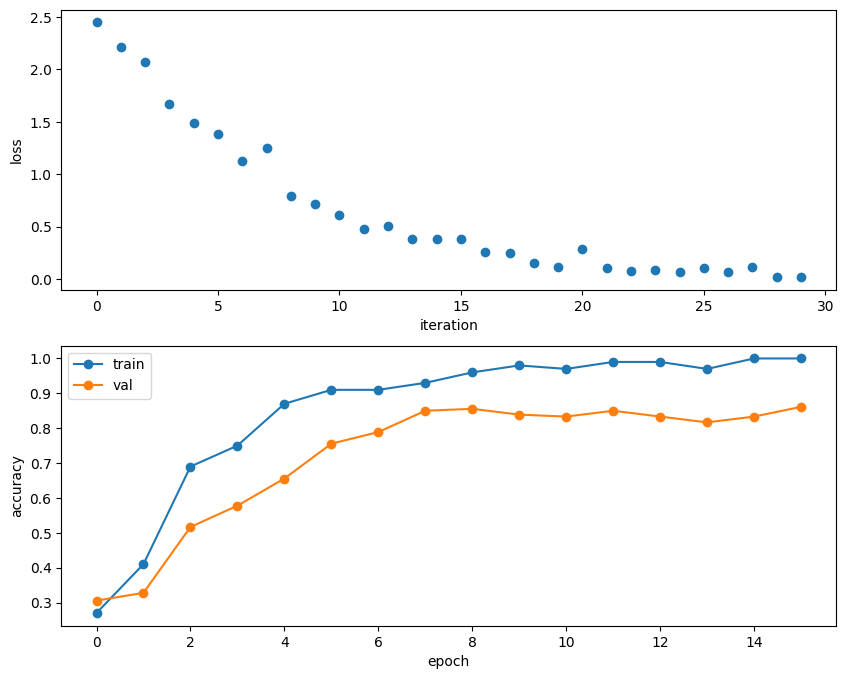

In [72]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, 'o')
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['train', 'val'], loc='upper left')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

Обучение сети на полном наборе данных. В шаблоне 1 эпоха для CIFAR-10 (49000 изображений, ~1000 итераций), в нашей обучающей выборке 1257 изображений, поэтому для сопоставимого числа итераций берем 10 эпох.

In [73]:
np.random.seed(231)
model = ThreeLayerConvNet(weight_scale=0.001, filter_size=3, num_filters=32, hidden_dim=500, reg=0.001)

solver = Solver(model, data,
                num_epochs=10, batch_size=50,
                update_rule='adam',
                optim_config={
                  'learning_rate': 1e-3,
                },
                verbose=True, print_every=20, num_train_samples=None)
solver.train()

(Iteration 1 / 250) loss: 2.302715
(Epoch 0 / 10) train acc: 0.161496; val_acc: 0.150000


(Iteration 21 / 250) loss: 2.178170


(Epoch 1 / 10) train acc: 0.207637; val_acc: 0.216667


(Iteration 41 / 250) loss: 1.484920


(Epoch 2 / 10) train acc: 0.764519; val_acc: 0.711111


...

(Epoch 8 / 10) train acc: 0.968178; val_acc: 0.927778
(Iteration 201 / 250) loss: 0.199835


(Iteration 221 / 250) loss: 0.183111


(Epoch 9 / 10) train acc: 0.972156; val_acc: 0.944444


(Iteration 241 / 250) loss: 0.167567


(Epoch 10 / 10) train acc: 0.975338; val_acc: 0.927778


In [74]:
print(
    'Full data training accuracy:',
    solver.check_accuracy(data['X_train'], data['y_train'])
)

Full data training accuracy: 0.9721559268098647


In [75]:
print(
    'Full data validation accuracy:',
    solver.check_accuracy(data['X_val'], data['y_val'])
)
print(
    'Full data test accuracy:',
    solver.check_accuracy(data['X_test'], data['y_test'])
)

Full data validation accuracy:

 0.9444444444444444
Full data test accuracy: 0.9472222222222222


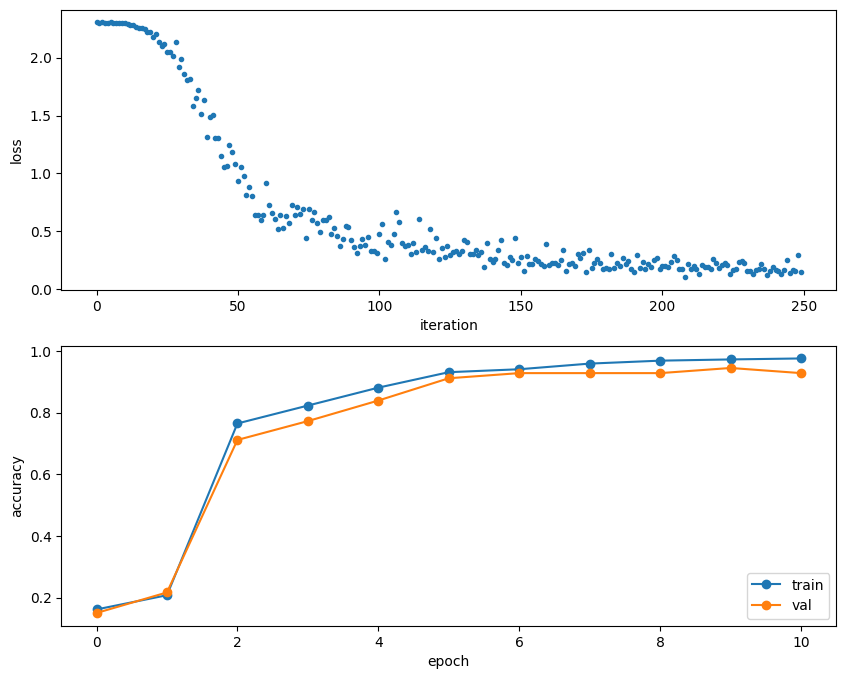

In [76]:
plt.subplot(2, 1, 1)
plt.plot(solver.loss_history, '.')
plt.xlabel('iteration')
plt.ylabel('loss')

plt.subplot(2, 1, 2)
plt.plot(solver.train_acc_history, '-o')
plt.plot(solver.val_acc_history, '-o')
plt.legend(['train', 'val'], loc='lower right')
plt.xlabel('epoch')
plt.ylabel('accuracy')
plt.show()

Фильтры первого слоя обученной сети (32 фильтра 3x3).

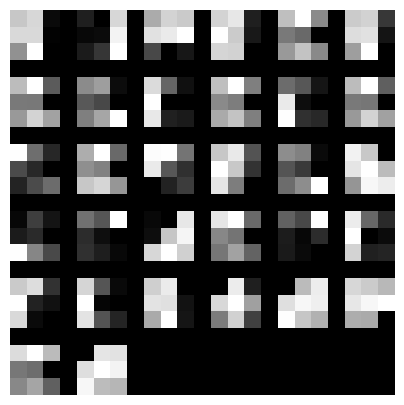

In [77]:
grid = visualize_grid(model.params['W1'].transpose(0, 2, 3, 1))
plt.imshow(grid.astype('uint8').squeeze(), cmap='gray')
plt.axis('off')
plt.gcf().set_size_inches(5, 5)
plt.show()

## Выводы

1. Реализованы в модульном виде слои: полносвязный, ReLU, батч-нормализация, dropout, свертка, max-pooling, функции потерь softmax и SVM, а также правила обновления весов SGD, SGD + momentum, RMSProp и Adam. Все реализации проверены численным градиентом, ошибки соответствуют ожидаемым (как правило, 1e-7 и меньше).
2. Быстрые реализации свертки и пулинга (im2col через as_strided, col2im, reshape) сделаны на numpy без Cython, совпадают с наивными (разница ~1e-13) и работают в 1.4-3.5 раза быстрее.
3. Двухслойная сеть, обученная через Solver, дает 96.1% на валидации (требовалось не менее 50%). Глубокие сети очень чувствительны к масштабу инициализации и шагу обучения, что показали эксперименты с переобучением и сравнение SGD/momentum.
4. Лучший оптимизатор - Adam, батч-нормализация ускоряет обучение глубокой сети в несколько раз и улучшает итоговую точность, а dropout на нашем наборе существенного выигрыша не дал.
5. Лучшая полносвязная сеть (2 скрытых слоя по 256 нейронов, батч-нормализация, Adam): **val accuracy 98.9%, test accuracy 98.1%**.
6. Трехслойная сверточная сеть (conv 3x3 - relu - pool - affine - relu - affine) легко переобучается на 100 изображениях (train 100%, val 86%), на полном наборе за 10 эпох получено train 97.2%, val 94.4%, test 94.7%. На изображениях 8x8 у сверточной сети мало пространства для извлечения признаков (после пулинга остается карта 4x4), поэтому здесь она не превосходит хорошо настроенную полносвязную сеть с BN; преимущества CNN сильнее проявляются на изображениях большего размера.